# SNEMI3D: can per-voxel features tell instances apart?

`proc_SNEMI3D.ipynb` converted every instance **one at a time** (instance → skeleton / wiremesh / gaussian). Here the
three representations are **pooled over all instances of a block** and every voxel asks them, without being told its
own label:

| representation | the question a voxel asks | features (nm) |
|---|---|---|
| **gaussian** | which blob explains me best? | blob mean, soft blob mean, Mahalanobis², log density, responsibility entropy, blob axis and size |
| **wiremesh** | where is the closest surface? | closest point, signed distance, direction surface → voxel |
| **frame** (skeleton) | where is the closest axis? | closest axis point, arc length, radius, distance and distance / radius, axis direction |

The question is **instance segmentation**: if you throw the instance ids away and only keep these per-voxel features,
can a clustering recover the instances? Two things are measured:

1. **Decoding** (sections 5): the closest primitive knows which instance it came from; how often does the voxel get the
   right owner, and where does it fail (the contacts between instances)?
2. **Owner-blind discrimination** (sections 6-7): no ids at all. For two adjacent voxels, does a feature jump tell us
   they belong to different instances (AUC per channel and per group), and does a graph clustering of those jumps
   give back the instances (adapted Rand error, variation of information)?

This is the round trip *instance → representation → instance*, the same idea as the drawing-back IoU in
`proc_SNEMI3D.ipynb`, but per voxel. It measures what the representations **can** encode; the primitives themselves are
built from the ground-truth instances, so it is not a segmentation method for raw EM.

In [1]:
import os, re, sys, time, warnings
from pathlib import Path

for v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS"):         # a 256-core machine overflows the 128 threads OpenBLAS was built for
    os.environ.setdefault(v, "64")

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy import sparse
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree, dijkstra
from sklearn.metrics import roc_auc_score, average_precision_score, adjusted_rand_score

# ---- parameters: change and re-run ------------------------------------------------------------
LABELS = "AC4_labels.h5"           # data/SNEMI3D/<file>; the voxel size is parsed from docs/DATASETS.md
BLOCK_ORIGIN = (30, 352, 352)      # first voxel of the block, array order (z, y, x)
BLOCK_SHAPE = (32, 320, 320)       # block size in voxels (z, y, x); 32 x 320 x 320 = 3.3 M voxels
VOX_PER_BLOB = 3000                # instance -> gaussian: about one blob per this many voxels
BLOB_RANGE = (1, 48)               # fewest and most blobs of one instance
INSET_NM = 0.5                     # wiremesh: every mesh is shrunk by this much along its vertex normals (section 3)
SAMPLE_NM = 6.0                    # the skeleton is sampled every ~6 nm so "closest axis point" is a point query
MIN_SEG = 200                      # clustering: segments under this many voxels are merged into their best neighbour
CUT_QUANTILES = (0.50, 0.80, 0.90, 0.95, 0.98, 0.99, 0.995, 0.999, 0.9999)   # clustering sweep (see section 7)
WORKERS = 1                        # processes for section 2 (1 = run in this process; the block is small enough)
SEED = 0
# -----------------------------------------------------------------------------------------------


def find_repo(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "docs" / "DATASETS.md").is_file():
            return p
    raise FileNotFoundError("Open this notebook from inside the ncntm repo (docs/DATASETS.md not found).")


REPO = find_repo()
sys.path.insert(0, str(REPO))
from ncntm.viz.grid import VoxelGrid
from ncntm.viz import convert as C
from ncntm.viz.types import Skeleton

DATA = Path(os.environ.get("NCNTM_DATA_DIR", REPO / "data")) / "SNEMI3D"
DOC_TEXT = (REPO / "docs" / "DATASETS.md").read_text()
crop_name = LABELS.split("_labels")[0] + "_em"
row = next(l for l in DOC_TEXT.splitlines() if l.startswith("|") and f"| {crop_name} |" in l)
vx, vy, vz = (float(v) for v in re.findall(r"[\d.]+", row.split("|")[8]))
VOX_ZYX = (vz, vy, vx)
print("repo :", REPO)
print("data :", DATA / LABELS)
print("voxel:", f"{vx:g} x {vy:g} x {vz:g} nm (x, y, z)")

repo : /home/nvidia/ncntm
data : /home/nvidia/ncntm/data/SNEMI3D/AC4_labels.h5
voxel: 6 x 6 x 30 nm (x, y, z)


## 1. A block of labels

A block of the labelled volume is cut out; instances are cut by the block walls, and one instance may appear as several
pieces. Background (label 0, the membrane gaps) carries no instance: it is not asked, not scored.

320 x 320 x 32 voxels (x, y, z) of 6 x 6 x 30 nm = 1.92 x 1.92 x 0.96 um, anisotropy 5:1
64 instances, 2,895,081 labelled voxels (88.4%), background 11.6%; voxels per instance: max 721,368, median 19,026, min 23


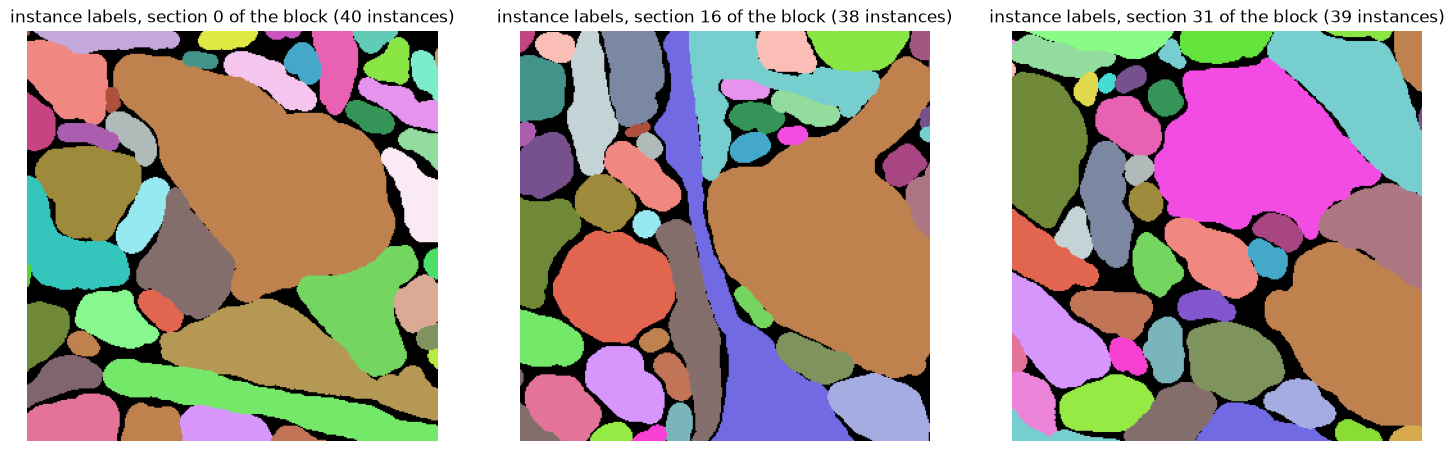

In [2]:
z0, y0, x0 = BLOCK_ORIGIN
nz, ny, nx = BLOCK_SHAPE
LAB = h5py.File(DATA / LABELS, "r")["main"][z0:z0 + nz, y0:y0 + ny, x0:x0 + nx].astype(np.int32)
GRID = VoxelGrid(LAB.shape, VOX_ZYX)
FG = LAB > 0                                                  # voxels that belong to an instance
IDS, COUNTS = np.unique(LAB[FG], return_counts=True)
order = np.argsort(-COUNTS)
IDS, COUNTS = IDS[order], COUNTS[order]                       # largest first
print(GRID.describe())
print(f"{len(IDS)} instances, {FG.sum():,} labelled voxels ({FG.mean():.1%}), background {1 - FG.mean():.1%}; "
      f"voxels per instance: max {COUNTS.max():,}, median {int(np.median(COUNTS)):,}, min {COUNTS.min():,}")

rng = np.random.default_rng(SEED)
RAND = rng.random((int(LAB.max()) + 1, 3)) * 0.8 + 0.2
RAND[0] = 0

fig, axs = plt.subplots(1, 3, figsize=(18, 6.2))
for a, k in zip(axs, (0, nz // 2, nz - 1)):
    a.imshow(RAND[LAB[k]], aspect=vy / vx)
    a.set_title(f"instance labels, section {k} of the block ({int(len(np.unique(LAB[k])) - 1)} instances)")
    a.axis("off")
plt.show()

## 2. Instance → skeleton, wiremesh, gaussian

The three converters of `ncntm.viz.convert`, once per instance, on the whole block grid so that every result is
already in the **block frame** (nm, x y z): no per-instance offsets to carry around. The number of blobs is
proportional to the instance size (`VOX_PER_BLOB`). A piece too small for a skeleton or a mesh falls back to one
ball (skeleton) or none (mesh).

In [3]:
import multiprocessing as mp
from threadpoolctl import threadpool_limits


def blobs_for(n):
    return int(np.clip(round(n / VOX_PER_BLOB), *BLOB_RANGE))


def build_one(i):
    mask = LAB == i
    n = int(mask.sum())
    rec = dict(id=int(i), n=n)
    try:
        sk = C.instance_to_skeleton(mask, GRID, dust_nm3=0.0, instance_id=i)
    except ValueError:                                         # too small: one ball at the centroid
        pts = GRID.voxel_centers_nm(np.argwhere(mask))
        r = (3 * n * float(np.prod(GRID.voxel_size_xyz_nm)) / (4 * np.pi)) ** (1 / 3)
        sk = Skeleton(pts.mean(0, keepdims=True), np.zeros((0, 2), np.int32), np.array([r]), instance_id=int(i))
        rec["skel_fallback"] = True
    try:
        mesh = C.instance_to_mesh(mask, GRID, instance_id=i)
    except Exception as err:
        mesh, rec["mesh_error"] = None, f"{type(err).__name__}: {err}"[:100]
    g = C.instance_to_gaussians(mask, GRID, k=min(blobs_for(n), n), instance_id=i)
    return rec, sk, mesh, g


def _one_thread():
    threadpool_limits(1)                                       # one BLAS thread per worker, or 32 workers fight for the cores


def _work(i):
    return build_one(int(i))


t0 = time.time()
if WORKERS > 1:
    with mp.get_context("fork").Pool(min(WORKERS, os.cpu_count()), initializer=_one_thread) as pool:   # fork: workers share LAB
        built = pool.map(_work, [int(i) for i in IDS], chunksize=1)
else:
    built = [_work(i) for i in IDS]
REC = pd.DataFrame([b[0] for b in built]).set_index("id")
SKELS = {int(i): b[1] for i, b in zip(IDS, built)}
MESHES = {int(i): b[2] for i, b in zip(IDS, built) if b[2] is not None}
GAUSS = {int(i): b[3] for i, b in zip(IDS, built)}
print(f"converted {len(IDS)} instances in {time.time() - t0:.0f} s: "
      f"{sum(len(g) for g in GAUSS.values())} blobs, {sum(len(s.vertices_xyz_nm) for s in SKELS.values()):,} skeleton nodes, "
      f"{sum(len(m.faces) for m in MESHES.values()):,} mesh faces; "
      f"{int(REC.get('skel_fallback', pd.Series(dtype=bool)).fillna(False).sum())} skeleton fallbacks, "
      f"{len(IDS) - len(MESHES)} without a mesh")

converted 64 instances in 9 s: 771 blobs, 7,761 skeleton nodes, 2,161,976 mesh faces; 0 skeleton fallbacks, 0 without a mesh


## 3. Pool the primitives of all instances

From here on the primitives of the whole block form **one** gaussian mixture, **one** triangle soup and **one** set of
skeleton points. Each primitive still remembers which instance made it (`*_OWN`), but only the decoding in section 5
and the scoring look at that; the features of section 4 do not.

* **gaussian**: weight of a blob = share of the block's labelled voxels it represents.
* **wiremesh**: all vertices and faces in one array (a GPU `warp.Mesh` is built for the closest-surface query). Two
  instances that touch have **coincident faces** (the contact surface is meshed once from each side), so the closest
  face of a voxel near a contact is a tie and may belong to the neighbour. Shrinking each mesh by `INSET_NM` (0.5 nm,
  a twelfth of a voxel) along its vertex normals breaks the tie in favour of the voxel's own surface; the tied version
  is kept for comparison.
* **frame**: every skeleton edge is sampled every `SAMPLE_NM`, each sample carries its radius, arc length from the root
  of its tree, and axis direction.

In [4]:
# ---- gaussian
CNT = dict(zip(IDS.tolist(), COUNTS.tolist()))
G_MU, G_COV, G_LOGW, G_OWN, G_ROT, G_SIG = [], [], [], [], [], []
for i in IDS:
    g = GAUSS[int(i)]
    rot, sig = g.principal_axes()                              # columns of rot ascending in sigma
    G_MU.append(g.means_xyz_nm)
    G_COV.append(g.covariances_nm2)
    G_LOGW.append(np.log(g.weights * CNT[int(i)] / COUNTS.sum()))
    G_OWN.append(np.full(len(g), int(i)))
    G_ROT.append(rot[:, :, 2])                                 # longest principal axis
    G_SIG.append(sig[:, ::-1])                                 # sigma descending: longest, middle, shortest
G_MU, G_COV, G_LOGW, G_OWN, G_AXIS, G_SIG = (np.concatenate(a) for a in (G_MU, G_COV, G_LOGW, G_OWN, G_ROT, G_SIG))
G_PREC = np.linalg.inv(G_COV)
G_LOGDET = np.linalg.slogdet(G_COV)[1]

# ---- wiremesh
verts, tris, F_OWN, off = [], [], [], 0
for i in IDS:
    m = MESHES.get(int(i))
    if m is None:
        continue
    verts.append(m.vertices_xyz_nm)
    tris.append(np.asarray(m.faces) + off)
    F_OWN.append(np.full(len(m.faces), int(i)))
    off += len(m.vertices_xyz_nm)
M_VERTS_TIED = np.concatenate(verts).astype(np.float32)
M_TRIS = np.concatenate(tris).astype(np.int32)
F_OWN = np.concatenate(F_OWN)


def inset(vertices, faces, eps):
    # Move every vertex eps nm against its (area-weighted) vertex normal, i.e. into the instance.
    v, f = np.asarray(vertices, float), np.asarray(faces)
    fn = np.cross(v[f[:, 1]] - v[f[:, 0]], v[f[:, 2]] - v[f[:, 0]])
    vn = np.stack([sum(np.bincount(f[:, c], weights=fn[:, a], minlength=len(v)) for c in range(3)) for a in range(3)], axis=1)
    return v - eps * vn / np.maximum(np.linalg.norm(vn, axis=1, keepdims=True), 1e-12)


M_VERTS = inset(M_VERTS_TIED, M_TRIS, INSET_NM).astype(np.float32)


# ---- frame: skeleton edges sampled every SAMPLE_NM
def skeleton_samples(sk, spacing):
    v, e, r = np.asarray(sk.vertices_xyz_nm, float), np.asarray(sk.edges), np.asarray(sk.radii_nm, float)
    n = len(v)
    s = np.zeros(n)
    if len(e):
        L = np.linalg.norm(v[e[:, 1]] - v[e[:, 0]], axis=1)
        W = sparse.coo_matrix((L, (e[:, 0], e[:, 1])), shape=(n, n))
        W = (W + W.T).tocsr()
        _, comp = connected_components(W, directed=False)
        roots = np.unique(comp, return_index=True)[1]          # one root per tree
        s = dijkstra(W, directed=False, indices=roots, min_only=True)   # arc length from the root of its tree
        m = np.maximum(np.ceil(L / spacing).astype(int), 1)
        eid = np.repeat(np.arange(len(e)), m)
        k = np.arange(m.sum()) - np.repeat(np.cumsum(m) - m, m)
        t = ((k + 0.5) / np.repeat(m, m))[:, None]
        a, b = v[e[eid, 0]], v[e[eid, 1]]
        pts = a + (b - a) * t
        rad = r[e[eid, 0]] * (1 - t[:, 0]) + r[e[eid, 1]] * t[:, 0]
        arc = s[e[eid, 0]] * (1 - t[:, 0]) + s[e[eid, 1]] * t[:, 0]
        tan = (b - a) / np.maximum(L[eid], 1e-9)[:, None]
    else:
        pts, rad, arc, tan = (np.zeros((0, 3)), np.zeros(0), np.zeros(0), np.zeros((0, 3)))
    iso = np.flatnonzero(np.bincount(e.ravel(), minlength=n) == 0) if len(e) else np.arange(n)
    return (np.concatenate([pts, v[iso]]), np.concatenate([rad, r[iso]]),
            np.concatenate([arc, s[iso]]), np.concatenate([tan, np.zeros((len(iso), 3))]))


S_PTS, S_RAD, S_ARC, S_TAN, S_OWN = [], [], [], [], []
for i in IDS:
    p, r, a, t = skeleton_samples(SKELS[int(i)], SAMPLE_NM)
    S_PTS.append(p); S_RAD.append(r); S_ARC.append(a); S_TAN.append(np.abs(t)); S_OWN.append(np.full(len(p), int(i)))
S_PTS, S_RAD, S_ARC, S_TAN, S_OWN = (np.concatenate(a) for a in (S_PTS, S_RAD, S_ARC, S_TAN, S_OWN))
print(f"gaussian : {len(G_MU):,} blobs   | wiremesh: {len(M_TRIS):,} faces, {len(M_VERTS):,} vertices"
      f"   | frame: {len(S_PTS):,} axis samples (every {SAMPLE_NM:g} nm), radius {S_RAD.min():.0f}-{S_RAD.max():.0f} nm")

gaussian : 771 blobs   | wiremesh: 2,161,976 faces, 1,081,136 vertices   | frame: 17,971 axis samples (every 6 nm), radius 6-383 nm


## 4. Per-voxel features

For every labelled voxel centre `p` (nm):

* **gaussian** (`g_*`): the 16 blobs with the nearest means are scored by `log π_k N(p; μ_k, Σ_k)`; the best one
  gives its mean `g_mu*`, Mahalanobis² `g_d2`, the length of its longest axis `g_s1..3` (σ, descending) and `|axis|`
  (`g_ax*`, sign-free); the posterior over the 16 gives `g_smu*` (soft mean), the entropy `g_ent` and the log density
  `g_logp`.
* **wiremesh** (`m_*`): closest point `m_q*` on the pooled triangle soup (GPU, `warp.Mesh`), signed distance `m_sd`
  (negative when the voxel lies behind the face, i.e. inside), unit direction surface → voxel `m_u*`, `m_d = |m_sd|`.
* **frame** (`f_*`): closest skeleton sample `f_a*`, its arc length `f_s`, radius `f_r`, the distance `f_d`, the
  radius-normalised distance `f_dr = f_d / f_r`, and `|tangent|` (`f_t*`).
* **position** (`p*`): the voxel centre itself, the control.

In [5]:
KJI = np.argwhere(FG)                                          # (N, 3) array indices of the labelled voxels, C order
P = GRID.voxel_centers_nm(KJI)                                 # (N, 3) centres, (x, y, z) nm
N = len(P)
LAB_N = LAB[FG]                                                # GT instance id of every row
F = {"px": P[:, 0], "py": P[:, 1], "pz": P[:, 2]}              # the feature table: channel -> (N,) float32
DEC = {}                                                       # decoded owner of every row, per method


def gaussian_features(P, k_cand=16, chunk=200_000):
    tree = cKDTree(G_MU)
    k_cand = min(k_cand, len(G_MU))
    keys = ["g_mux", "g_muy", "g_muz", "g_smux", "g_smuy", "g_smuz", "g_d2", "g_logp", "g_ent",
            "g_ax", "g_ay", "g_az", "g_s1", "g_s2", "g_s3"]
    out = {k: np.empty(len(P), np.float32) for k in keys}
    gid = np.empty(len(P), np.int32)
    for a in range(0, len(P), chunk):
        p = P[a:a + chunk]
        cand = tree.query(p, k=k_cand)[1].reshape(len(p), -1)
        d = p[:, None, :] - G_MU[cand]
        m2 = np.einsum("nki,nkij,nkj->nk", d, G_PREC[cand], d)
        lp = G_LOGW[cand] - 0.5 * m2 - 0.5 * G_LOGDET[cand] - 1.5 * np.log(2 * np.pi)
        top = lp.argmax(1)
        rows = np.arange(len(p))
        g = cand[rows, top]
        mx = lp.max(1, keepdims=True)
        post = np.exp(lp - mx)
        z = post.sum(1, keepdims=True)
        post /= z
        sl = slice(a, a + len(p))
        gid[sl] = g
        out["g_d2"][sl] = m2[rows, top]
        out["g_logp"][sl] = (mx + np.log(z))[:, 0]
        out["g_ent"][sl] = -(post * np.log(np.maximum(post, 1e-12))).sum(1)
        soft = np.einsum("nk,nkc->nc", post, G_MU[cand])
        for c, name in enumerate("xyz"):
            out[f"g_mu{name}"][sl] = G_MU[g, c]
            out[f"g_smu{name}"][sl] = soft[:, c]
            out[f"g_a{name}"][sl] = np.abs(G_AXIS[g, c])
        for c in range(3):
            out[f"g_s{c + 1}"][sl] = G_SIG[g, c]
    return out, gid


t0 = time.time()
gf, G_ID = gaussian_features(P)
F.update(gf)
DEC["gaussian"] = G_OWN[G_ID]
print(f"gaussian features: {time.time() - t0:.0f} s")

gaussian features: 7 s


In [6]:
import warp as wp
wp.config.quiet = True
wp.init()
DEV = "cuda:0" if wp.get_cuda_device_count() else "cpu"


@wp.kernel
def closest_face(mesh: wp.uint64, pts: wp.array(dtype=wp.vec3), verts: wp.array(dtype=wp.vec3), tri: wp.array(dtype=wp.int32),
                 face: wp.array(dtype=wp.int32), sdist: wp.array(dtype=wp.float32), hit: wp.array(dtype=wp.vec3)):
    t = wp.tid()
    p = pts[t]
    q = wp.mesh_query_point_no_sign(mesh, p, 1.0e9)
    c = wp.mesh_eval_position(mesh, q.face, q.u, q.v)
    a = verts[tri[3 * q.face]]
    b = verts[tri[3 * q.face + 1]]
    d = verts[tri[3 * q.face + 2]]
    n = wp.normalize(wp.cross(b - a, d - a))                   # outward normal (counter-clockwise seen from outside)
    r = p - c
    sgn = float(1.0)
    if wp.dot(n, r) < 0.0:
        sgn = -1.0
    face[t] = q.face
    sdist[t] = sgn * wp.length(r)
    hit[t] = c


def mesh_features(P, vertices, chunk=1_000_000):
    verts = wp.array(vertices, dtype=wp.vec3, device=DEV)
    tri = wp.array(M_TRIS.ravel(), dtype=wp.int32, device=DEV)
    mesh = wp.Mesh(points=verts, indices=tri)
    face = np.empty(len(P), np.int32)
    sd = np.empty(len(P), np.float32)
    hit = np.empty((len(P), 3), np.float32)
    for a in range(0, len(P), chunk):
        p = wp.array(P[a:a + chunk].astype(np.float32), dtype=wp.vec3, device=DEV)
        f = wp.empty(len(p), dtype=wp.int32, device=DEV)
        s = wp.empty(len(p), dtype=wp.float32, device=DEV)
        h = wp.empty(len(p), dtype=wp.vec3, device=DEV)
        wp.launch(closest_face, dim=len(p), inputs=[mesh.id, p, verts, tri, f, s, h], device=DEV)
        face[a:a + chunk], sd[a:a + chunk], hit[a:a + chunk] = f.numpy(), s.numpy(), h.numpy()
    return face, sd, hit


t0 = time.time()
M_FACE_TIED = mesh_features(P, M_VERTS_TIED)[0]                # tied: coincident faces of touching instances
M_FACE, sd, hit = mesh_features(P, M_VERTS)                    # inset: the voxel's own surface wins
u = (P - hit) / np.maximum(np.linalg.norm(P - hit, axis=1), 1e-6)[:, None]   # unit vector surface point -> voxel
for c, name in enumerate("xyz"):
    F[f"m_q{name}"] = hit[:, c]
    F[f"m_u{name}"] = u[:, c].astype(np.float32)
F["m_sd"] = sd
F["m_d"] = np.abs(sd)
DEC["wiremesh (tied)"] = F_OWN[M_FACE_TIED]
DEC["wiremesh"] = F_OWN[M_FACE]
print(f"wiremesh features ({DEV}): {time.time() - t0:.0f} s; voxels in front of their closest face (sd > 0): {(sd > 0).mean():.2%}")

Warp 1.19.0 initialized:
   CUDA Toolkit 13.4, Driver 13.5
   Devices:
     "cpu"      : "CPU"
     "cuda:0"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:1"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:2"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:3"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:4"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:5"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:6"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:7"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
   CUDA peer access:
     Supported fully (all-directional)
   Kernel cache:
     /home/nvidia/.cache/warp/1.19.0
Module __main__ f443159 load on device 'cuda:0' took 1.15 ms  (cached)
wiremesh features (cuda:0): 1 s; voxels in front of their closest face (sd > 0): 0.00%


In [7]:
def frame_features(P):
    # closest axis sample (the feature) ...
    d1, j = cKDTree(S_PTS).query(P, k=1)
    # ... and, for the decoding, the sample that minimises d / r and d - r over ALL samples (exact, brute force on the GPU):
    # the samples nearest to a voxel all lie on one axis, so a nearest-neighbour search cannot offer the fat axis farther away.
    import torch
    dev = "cuda:0" if torch.cuda.is_available() else "cpu"
    S = torch.as_tensor(S_PTS, dtype=torch.float32, device=dev)
    R = torch.as_tensor(np.maximum(S_RAD, 1.0), dtype=torch.float32, device=dev)
    jr, jm = np.empty(len(P), np.int64), np.empty(len(P), np.int64)
    for a in range(0, len(P), 40_000):
        d = torch.cdist(torch.as_tensor(P[a:a + 40_000], dtype=torch.float32, device=dev), S)
        jr[a:a + 40_000] = (d / R).argmin(1).cpu().numpy()
        jm[a:a + 40_000] = (d - R).argmin(1).cpu().numpy()
    return j, d1, jr, jm


t0 = time.time()
S_ID, f_d, S_ID_R, S_ID_M = frame_features(P)
for c, name in enumerate("xyz"):
    F[f"f_a{name}"] = S_PTS[S_ID, c].astype(np.float32)
    F[f"f_t{name}"] = S_TAN[S_ID, c].astype(np.float32)
F["f_s"] = S_ARC[S_ID].astype(np.float32)
F["f_r"] = S_RAD[S_ID].astype(np.float32)
F["f_d"] = f_d.astype(np.float32)
F["f_dr"] = (f_d / np.maximum(S_RAD[S_ID], 1.0)).astype(np.float32)
DEC["frame"] = S_OWN[S_ID]
DEC["frame (d / r)"] = S_OWN[S_ID_R]
DEC["frame (d - r)"] = S_OWN[S_ID_M]
F = {k: np.asarray(v, np.float32) for k, v in F.items()}
GROUPS = {
    "POS": ["px", "py", "pz"],
    "GAU": ["g_mux", "g_muy", "g_muz", "g_smux", "g_smuy", "g_smuz", "g_d2", "g_logp", "g_ent", "g_ax", "g_ay", "g_az", "g_s1", "g_s2", "g_s3"],
    "MESH": ["m_qx", "m_qy", "m_qz", "m_sd", "m_d", "m_ux", "m_uy", "m_uz"],
    "FRAME": ["f_ax", "f_ay", "f_az", "f_s", "f_r", "f_d", "f_dr", "f_tx", "f_ty", "f_tz"],
}
ANCHOR = {"POS": ["px", "py", "pz"], "GAU": ["g_mux", "g_muy", "g_muz"], "MESH": ["m_qx", "m_qy", "m_qz"], "FRAME": ["f_ax", "f_ay", "f_az"]}
print(f"frame features: {time.time() - t0:.0f} s;  {N:,} voxels x {len(F)} channels = {sum(v.nbytes for v in F.values()) / 1e9:.2f} GB")
print({g: len(c) for g, c in GROUPS.items()})

frame features: 7 s;  2,895,081 voxels x 36 channels = 0.42 GB
{'POS': 3, 'GAU': 15, 'MESH': 8, 'FRAME': 10}


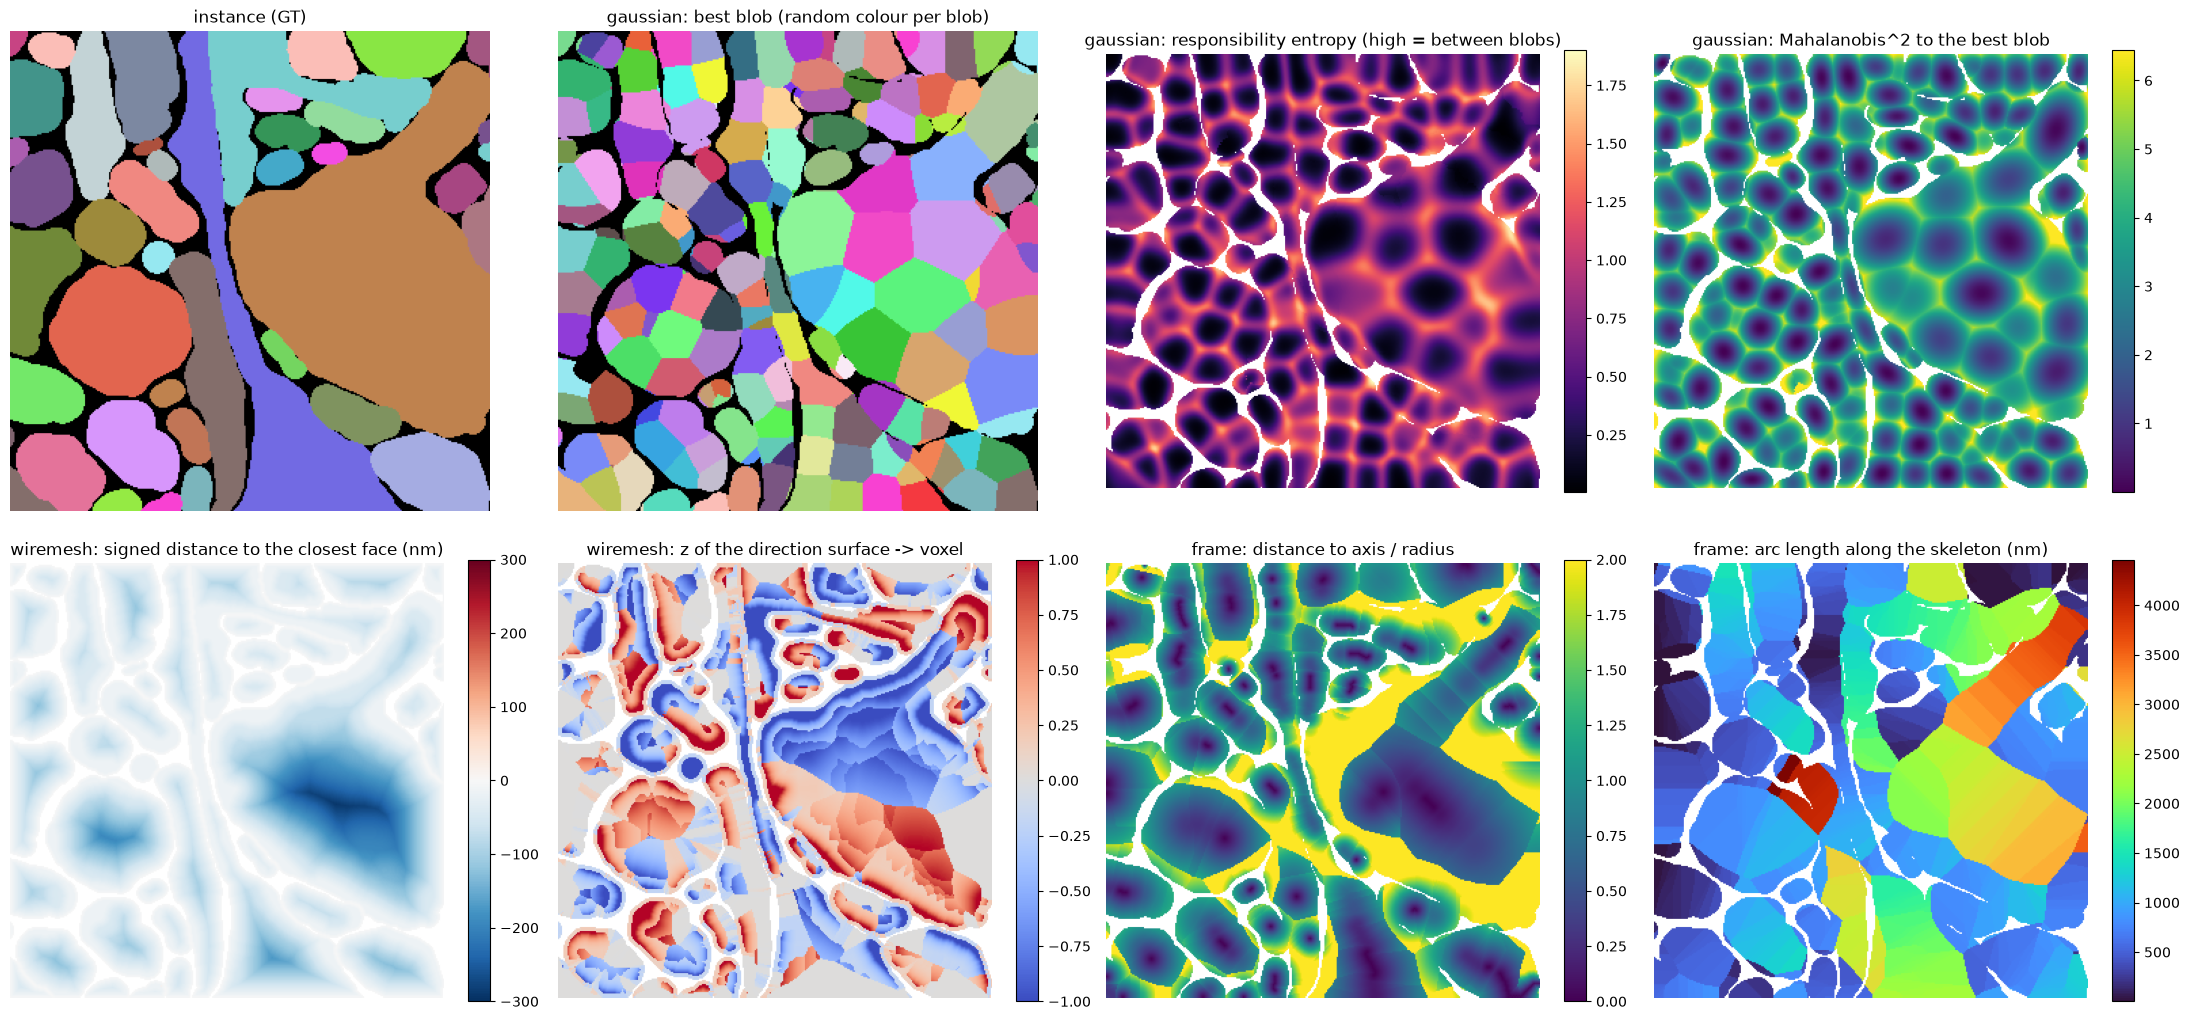

In [8]:
def volume(values, fill=np.nan):
    v = np.full(LAB.shape, fill, np.float32)
    v[FG] = values
    return v


def rgb_of(ids_vol):
    return RAND[ids_vol % len(RAND)] * (ids_vol[..., None] > 0)


k = nz // 2
fig, axs = plt.subplots(2, 4, figsize=(22, 10.5))
asp = vy / vx
axs[0, 0].imshow(RAND[LAB[k]], aspect=asp); axs[0, 0].set_title("instance (GT)")
blob_vol = np.zeros(LAB.shape, np.int64); blob_vol[FG] = G_ID + 1
axs[0, 1].imshow(rgb_of(blob_vol[k]), aspect=asp); axs[0, 1].set_title("gaussian: best blob (random colour per blob)")
im = axs[0, 2].imshow(volume(F["g_ent"])[k], cmap="magma", aspect=asp); axs[0, 2].set_title("gaussian: responsibility entropy (high = between blobs)")
plt.colorbar(im, ax=axs[0, 2], fraction=0.046)
im = axs[0, 3].imshow(volume(F["g_d2"])[k], cmap="viridis", aspect=asp, vmax=np.nanpercentile(F["g_d2"], 99)); axs[0, 3].set_title("gaussian: Mahalanobis^2 to the best blob")
plt.colorbar(im, ax=axs[0, 3], fraction=0.046)
im = axs[1, 0].imshow(volume(F["m_sd"])[k], cmap="RdBu_r", vmin=-300, vmax=300, aspect=asp); axs[1, 0].set_title("wiremesh: signed distance to the closest face (nm)")
plt.colorbar(im, ax=axs[1, 0], fraction=0.046)
im = axs[1, 1].imshow(volume(F["m_uz"])[k], cmap="coolwarm", vmin=-1, vmax=1, aspect=asp); axs[1, 1].set_title("wiremesh: z of the direction surface -> voxel")
plt.colorbar(im, ax=axs[1, 1], fraction=0.046)
im = axs[1, 2].imshow(volume(F["f_dr"])[k], cmap="viridis", vmin=0, vmax=2, aspect=asp); axs[1, 2].set_title("frame: distance to axis / radius")
plt.colorbar(im, ax=axs[1, 2], fraction=0.046)
im = axs[1, 3].imshow(volume(F["f_s"])[k], cmap="turbo", aspect=asp); axs[1, 3].set_title("frame: arc length along the skeleton (nm)")
plt.colorbar(im, ax=axs[1, 3], fraction=0.046)
for a in axs.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

## 5. Decoding: closest primitive → owner

If every primitive carries the id of the instance that made it (which is how a dataset of these representations would be
stored), the voxel simply takes the id of its closest primitive: closest blob (maximum posterior), closest face,
closest axis sample. Two radius-aware variants take, among **all** axis samples, the one with the smallest distance
divided by radius (`frame (d / r)`) or the smallest distance minus radius (`frame (d - r)`, the closest tube
surface): a fat neurite should win over a thin one at the same distance. `wiremesh (tied)` is the closest face of the
raw meshes, where touching instances have coincident faces; `wiremesh` is the 0.5 nm inset version (section 3).

The accuracy is shown per distance to the nearest contact (a voxel with a neighbour of another label), because that is
where the primitives of two instances meet.

20.8% of the labelled voxels are contact voxels, 36.8% are more than 50 nm from any contact


,accuracy,contact_accuracy,interior_accuracy,are,voi_split,voi_merge
method,,,,,,
gaussian,0.9716,0.8758,1.0000,0.0395,0.1822,0.1869
wiremesh (tied),0.9549,0.9187,0.9822,0.0564,0.2128,0.2639
wiremesh,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000
frame,0.7040,0.5410,0.8307,0.5102,1.2279,0.8714
frame (d / r),0.9172,0.7447,0.9971,0.1128,0.3889,0.4461
frame (d - r),0.9049,0.7217,0.9961,0.1212,0.5019,0.4429


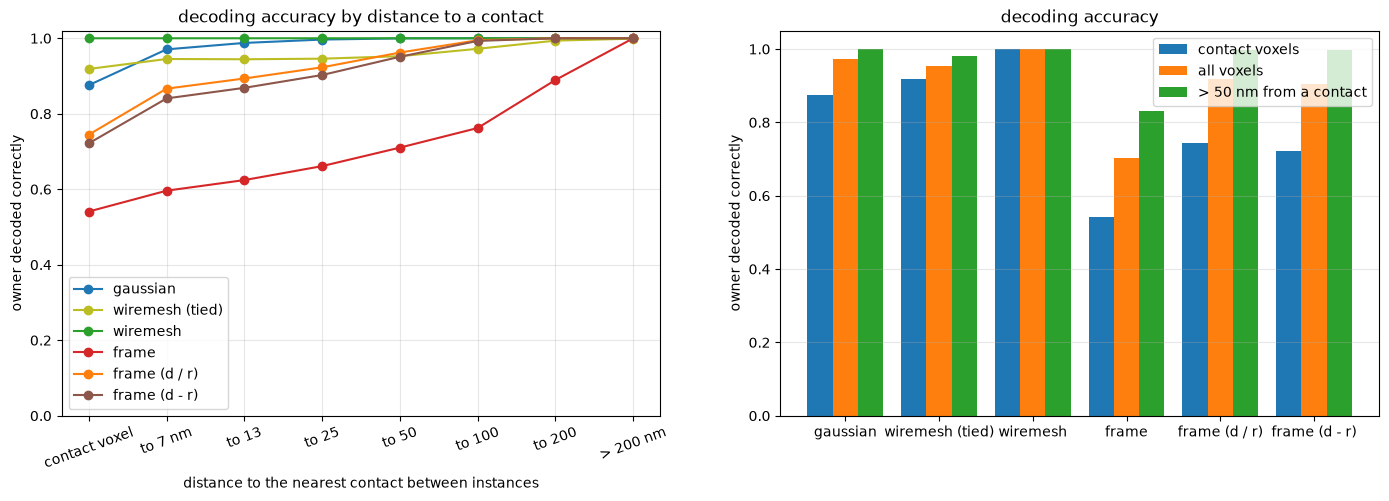

In [9]:
def seg_scores(pred, gt):
    # Contingency-table scores of a segmentation `pred` against `gt` (1-D label arrays over the same voxels).
    p = np.unique(pred, return_inverse=True)[1]
    g = np.unique(gt, return_inverse=True)[1]
    n = len(p)
    npj = int(p.max()) + 1
    ukey, nij = np.unique(g.astype(np.int64) * npj + p, return_counts=True)
    gi, pj = ukey // npj, ukey % npj
    s, t = np.bincount(g).astype(float), np.bincount(p).astype(float)
    sum2 = float((nij.astype(float) ** 2).sum())
    prec, rec = sum2 / (t ** 2).sum(), sum2 / (s ** 2).sum()    # pairs kept together that belong together / pairs that belong together and are kept
    return dict(are=1 - 2 * prec * rec / (prec + rec), precision=prec, recall=rec,
                voi_split=float(-(nij / n * np.log(nij / s[gi])).sum()),      # H(pred | gt): over-segmentation
                voi_merge=float(-(nij / n * np.log(nij / t[pj])).sum()),      # H(gt | pred): merges
                n_pred=int(npj), n_gt=int(len(s)))


# distance (nm) from every labelled voxel to the nearest contact voxel (a voxel with a 6-neighbour of another label)
contact = np.zeros(LAB.shape, bool)
for ax in range(3):
    lo, hi = [slice(None)] * 3, [slice(None)] * 3
    lo[ax], hi[ax] = slice(0, -1), slice(1, None)
    diff = LAB[tuple(lo)] != LAB[tuple(hi)]
    contact[tuple(lo)] |= diff
    contact[tuple(hi)] |= diff
BDIST = ndi.distance_transform_edt(~contact, sampling=VOX_ZYX)[FG]
BINS = [0, 1, 7, 13, 25, 50, 100, 200, 1e9]
BIN_LABEL = ["contact voxel", "to 7 nm", "to 13", "to 25", "to 50", "to 100", "to 200", "> 200 nm"]
bin_of = np.digitize(BDIST, BINS[1:-1], right=True)

DECODE = []
ACC_BY_BIN = {}
for name, owner in DEC.items():
    ok = owner == LAB_N
    sc = seg_scores(owner, LAB_N)
    DECODE.append(dict(method=name, accuracy=ok.mean(), contact_accuracy=ok[bin_of == 0].mean(), interior_accuracy=ok[BDIST > 50].mean(),
                       are=sc["are"], voi_split=sc["voi_split"], voi_merge=sc["voi_merge"]))
    ACC_BY_BIN[name] = [ok[bin_of == b].mean() for b in range(len(BIN_LABEL))]
DECODE = pd.DataFrame(DECODE).set_index("method")
print(f"{(bin_of == 0).mean():.1%} of the labelled voxels are contact voxels, {(BDIST > 50).mean():.1%} are more than 50 nm from any contact")
display(DECODE.style.format("{:.4f}"))

fig, axs = plt.subplots(1, 2, figsize=(17, 5))
cols = {"gaussian": "tab:blue", "wiremesh (tied)": "tab:olive", "wiremesh": "tab:green", "frame": "tab:red", "frame (d / r)": "tab:orange", "frame (d - r)": "tab:brown"}
for name, acc in ACC_BY_BIN.items():
    axs[0].plot(range(len(BIN_LABEL)), acc, "o-", color=cols[name], label=name)
axs[0].set_xticks(range(len(BIN_LABEL))); axs[0].set_xticklabels(BIN_LABEL, rotation=20)
axs[0].set_xlabel("distance to the nearest contact between instances"); axs[0].set_ylabel("owner decoded correctly")
axs[0].set_title("decoding accuracy by distance to a contact"); axs[0].legend(); axs[0].grid(alpha=0.3); axs[0].set_ylim(0, 1.02)
x = np.arange(len(DECODE))
w = 0.27
for o, (col, lab) in enumerate([("contact_accuracy", "contact voxels"), ("accuracy", "all voxels"), ("interior_accuracy", "> 50 nm from a contact")]):
    axs[1].bar(x + (o - 1) * w, DECODE[col], w, label=lab)
axs[1].set_xticks(x); axs[1].set_xticklabels(DECODE.index)
axs[1].set_ylim(0, 1.05); axs[1].set_ylabel("owner decoded correctly"); axs[1].legend(); axs[1].grid(axis="y", alpha=0.3)
axs[1].set_title("decoding accuracy")
plt.show()

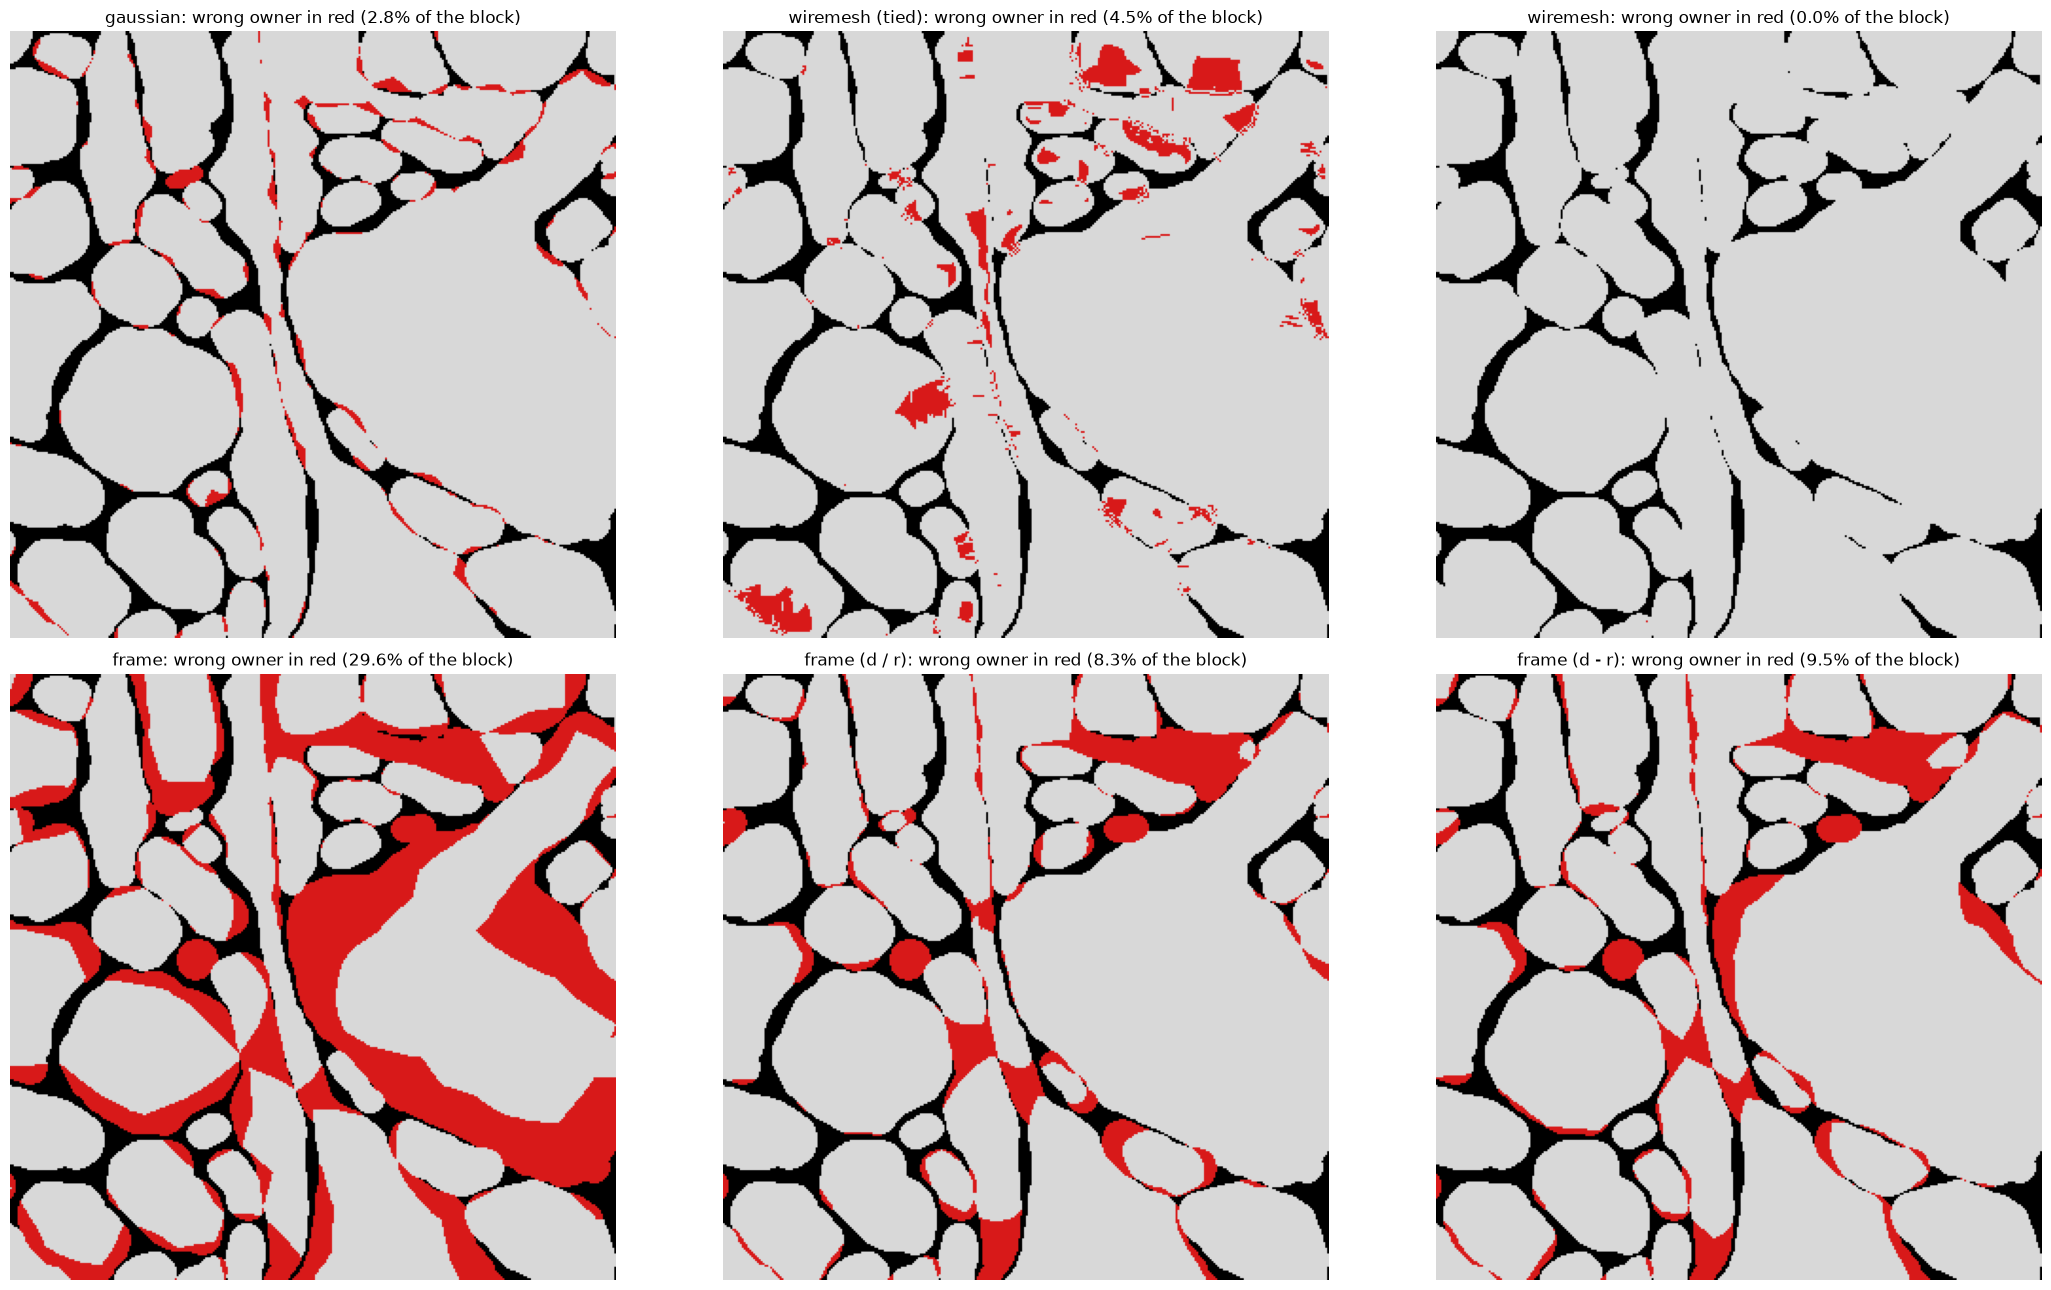

In [10]:
k = nz // 2
fig, axs = plt.subplots(2, 3, figsize=(22, 13))
for a, (name, owner) in zip(axs.ravel(), DEC.items()):
    ok = np.full(LAB.shape, 0, np.int8)
    ok[FG] = np.where(owner == LAB_N, 1, 2)
    img = np.zeros(LAB.shape[1:] + (3,))
    img[ok[k] == 1] = (0.85, 0.85, 0.85)
    img[ok[k] == 2] = (0.85, 0.1, 0.1)
    a.imshow(img, aspect=vy / vx)
    a.set_title(f"{name}: wrong owner in red ({(owner != LAB_N).mean():.1%} of the block)")
    a.axis("off")
plt.tight_layout()
plt.show()

## 6. Owner-blind discrimination: do adjacent voxels with different instances differ in their features?

Now every id is thrown away. The graph is the 6-neighbourhood of the labelled voxels; an edge is **different** when its
two voxels belong to different GT instances. Each feature channel `c` gives every edge a score `|c(a) - c(b)|`; if the
channel discriminates, different edges score higher than same edges. That is the **AUC** (0.5 = no information).

The block is split in two halves along x: the left half trains the learned affinity of the next cell, the right half is
where everything is scored.

8,272,828 edges (1.55% join different instances); train 3,969,680 (left half), test 4,294,408 (right half)
  edges along z: 2,600,090, different 4.02%
  edges along y: 2,833,580, different 0.45%
  edges along x: 2,839,158, different 0.39%


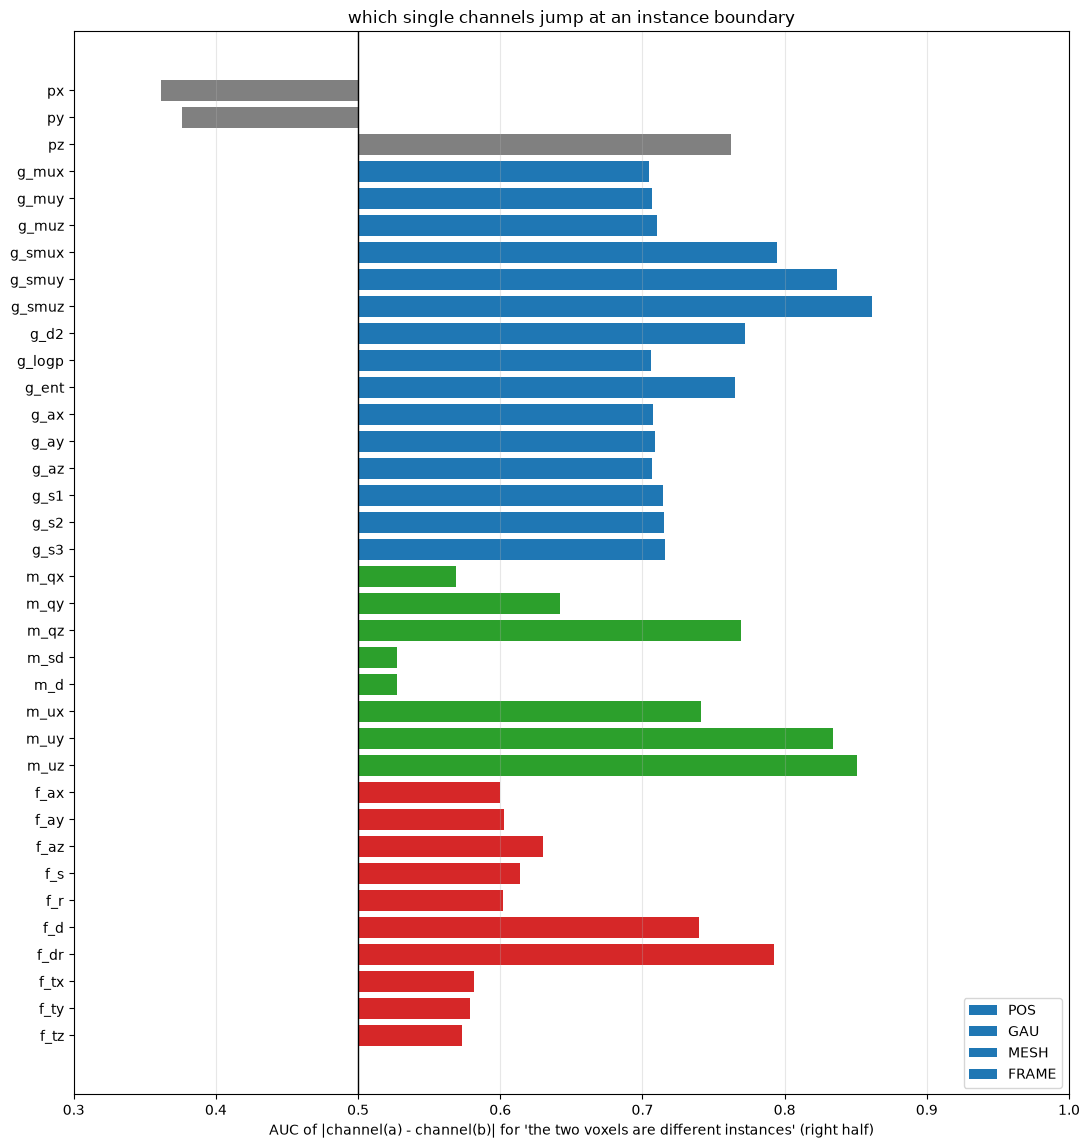

,group,auc
g_smuz,GAU,0.862
m_uz,MESH,0.851
g_smuy,GAU,0.836
m_uy,MESH,0.834
g_smux,GAU,0.795
f_dr,FRAME,0.793
g_d2,GAU,0.772
m_qz,MESH,0.769
g_ent,GAU,0.765
pz,POS,0.762


In [11]:
NID = np.full(LAB.shape, -1, np.int32)
NID[FG] = np.arange(N)
ea, eb, eax = [], [], []
for ax in range(3):
    lo, hi = [slice(None)] * 3, [slice(None)] * 3
    lo[ax], hi[ax] = slice(0, -1), slice(1, None)
    a_, b_ = NID[tuple(lo)], NID[tuple(hi)]
    ok = (a_ >= 0) & (b_ >= 0)
    ea.append(a_[ok]); eb.append(b_[ok]); eax.append(np.full(int(ok.sum()), ax, np.int8))
EA, EB, EAX = np.concatenate(ea), np.concatenate(eb), np.concatenate(eax)
DIFF = LAB_N[EA] != LAB_N[EB]
XI = KJI[:, 2]
HALF = nx // 2
TRAIN = (XI[EA] < HALF) & (XI[EB] < HALF)
TEST = (XI[EA] >= HALF) & (XI[EB] >= HALF)
print(f"{len(EA):,} edges ({DIFF.mean():.2%} join different instances); train {TRAIN.sum():,} (left half), test {TEST.sum():,} (right half)")
for ax, nm in enumerate("zyx"):
    print(f"  edges along {nm}: {(EAX == ax).sum():,}, different {DIFF[EAX == ax].mean():.2%}")


def delta(c, idx):
    return np.abs(F[c][EA[idx]] - F[c][EB[idx]])


ti = np.flatnonzero(TEST)
AUC = {}
for g, chs in GROUPS.items():
    for c in chs:
        AUC[c] = (g, roc_auc_score(DIFF[ti], delta(c, ti)))
AUC = pd.DataFrame(AUC, index=["group", "auc"]).T
AUC["auc"] = AUC["auc"].astype(float)

fig, ax = plt.subplots(figsize=(11, 0.28 * len(AUC) + 1.5))
gcol = {"POS": "gray", "GAU": "tab:blue", "MESH": "tab:green", "FRAME": "tab:red"}
ys = np.arange(len(AUC))[::-1]
ax.barh(ys, AUC.auc - 0.5, left=0.5, color=[gcol[g] for g in AUC.group])
ax.set_yticks(ys); ax.set_yticklabels(AUC.index)
ax.axvline(0.5, color="k", lw=1)
ax.set_xlim(0.3, 1.0); ax.set_xlabel("AUC of |channel(a) - channel(b)| for 'the two voxels are different instances' (right half)")
ax.set_title("which single channels jump at an instance boundary")
for g, c in gcol.items():
    ax.barh([], [], color=c, label=g)
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
display(AUC.sort_values("auc", ascending=False).head(12).style.format({"auc": "{:.3f}"}))

Single channels are weak or mixed. A **learned affinity** shows how much a group of channels holds together: a gradient
boosted classifier (trained on the left half) gets, for every edge, `|c(a) - c(b)|` and `(c(a) + c(b)) / 2` of every
channel of the group and the axis of the edge (z-steps are 5 times longer than x/y-steps and cross contacts differently,
so even the `POS` control gets that). Its probability of "different" is the edge weight of the next section.

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier


def edge_matrix(chs, idx):
    cols = []
    for c in chs:
        cols += [delta(c, idx), 0.5 * (F[c][EA[idx]] + F[c][EB[idx]])]
    cols.append(EAX[idx].astype(np.float32))
    return np.stack(cols, axis=1).astype(np.float32)


rng = np.random.default_rng(SEED)
tr = np.flatnonzero(TRAIN)
pos, neg = tr[DIFF[tr]], tr[~DIFF[tr]]
tr_sample = np.concatenate([rng.choice(pos, min(len(pos), 150_000), replace=False), rng.choice(neg, min(len(neg), 300_000), replace=False)])
LEARN_GROUPS = {**{g: GROUPS[g] for g in GROUPS}, "GAU+FRAME": GROUPS["GAU"] + GROUPS["FRAME"], "ALL": GROUPS["GAU"] + GROUPS["MESH"] + GROUPS["FRAME"]}
PRED, LEARNED = {}, []
t0 = time.time()
for g, chs in LEARN_GROUPS.items():
    clf = HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, random_state=SEED)
    clf.fit(edge_matrix(chs, tr_sample), DIFF[tr_sample])
    p = np.empty(len(ti), np.float32)
    for a in range(0, len(ti), 1_000_000):
        p[a:a + 1_000_000] = clf.predict_proba(edge_matrix(chs, ti[a:a + 1_000_000]))[:, 1]
    PRED[g] = p
    LEARNED.append(dict(group=g, channels=len(chs), auc=roc_auc_score(DIFF[ti], p), average_precision=average_precision_score(DIFF[ti], p)))
    print(f"  {g}: {time.time() - t0:.0f} s")
LEARNED = pd.DataFrame(LEARNED).set_index("group")
print(f"chance average precision = prevalence = {DIFF[ti].mean():.3f}")
display(LEARNED.style.format({"auc": "{:.3f}", "average_precision": "{:.3f}"}))

  POS: 4 s
  GAU: 10 s
  MESH: 15 s
  FRAME: 21 s
  GAU+FRAME: 32 s
  ALL: 44 s
chance average precision = prevalence = 0.014


,channels,auc,average_precision
group,,,
POS,3,0.761,0.044
GAU,15,0.924,0.261
MESH,8,1.000,1.000
FRAME,10,0.909,0.210
GAU+FRAME,25,0.963,0.431
ALL,33,1.000,1.000


## 7. Clustering the features into instances

The edge weights of the right half are turned into a segmentation the standard way:

1. build the **minimum spanning tree** of the voxel graph (single linkage: the tree edges are the only ones that can
   matter);
2. **cut** the tree edges heavier than a threshold (swept over quantiles of the tree weights, `CUT_QUANTILES`);
3. the connected pieces are segments; pieces under `MIN_SEG` voxels are merged into the neighbour they are best
   connected to.

Three kinds of weights: the **anchor jump** (unsupervised, in nm: how far apart are the closest blob mean / surface point
/ axis point of the two voxels), for the wiremesh also the **flip** (unsupervised: how much the unit direction surface →
voxel turns between the two voxels), and the **learned affinity** of the last section. `oracle` uses the GT "different"
flag as weight and shows what this clustering gives when the weights are perfect (the floor set by `MIN_SEG`). A
feature-space **k-means** with as many clusters as there are instances (no graph, no neighbours) is the other extreme.

Scores (against the GT instances of the right half): **adapted Rand error** `ARE = 1 - F`, `F` the harmonic mean of
pair precision (pairs kept together that belong together, so a low value means merges) and pair recall (low means
splits); and the **variation of information** split (over-segmentation) and merge (under-segmentation) parts.

In [13]:
RN = np.flatnonzero(XI >= HALF)                                # voxels of the right half
RMAP = np.full(N, -1, np.int64)
RMAP[RN] = np.arange(len(RN))
M = len(RN)
EA_T, EB_T = RMAP[EA[ti]], RMAP[EB[ti]]
GT_R = LAB_N[RN]
print(f"right half: {M:,} voxels, {len(np.unique(GT_R))} instances, {len(ti):,} edges")


def components(rows, cols, n):
    g = sparse.coo_matrix((np.ones(len(rows), np.int8), (rows, cols)), shape=(n, n))
    return connected_components(g, directed=False)[1]


def merge_small(lab, w, min_size, rounds=10):
    # Every segment under min_size takes the neighbour it is connected to by its lightest edge.
    for _ in range(rounds):
        size = np.bincount(lab)
        la, lb = lab[EA_T], lab[EB_T]
        cross = la != lb
        la, lb, ww = la[cross], lb[cross], w[cross]
        s1, s2 = size[la] < min_size, size[lb] < min_size
        src = np.concatenate([la[s1], lb[s2]])
        if len(src) == 0:
            break
        dst = np.concatenate([lb[s1], la[s2]])
        wt = np.concatenate([ww[s1], ww[s2]])
        o = np.lexsort((wt, src))
        src, dst = src[o], dst[o]
        first = np.r_[True, src[1:] != src[:-1]]               # lightest edge of every small segment
        g = sparse.coo_matrix((np.ones(int(first.sum()), np.int8), (src[first], dst[first])), shape=(len(size),) * 2)
        lab = connected_components(g, directed=False)[1][lab]
    return lab


def cluster_sweep(name, w):
    # Minimum spanning tree of the right half under weights w, cut at CUT_QUANTILES of the tree weights.
    mst = minimum_spanning_tree(sparse.coo_matrix((w.astype(np.float64) + 1e-9, (EA_T, EB_T)), shape=(M, M)).tocsr()).tocoo()
    rows, cols, data = mst.row, mst.col, mst.data
    out, best = [], (9.0, None)
    for q in CUT_QUANTILES:
        keep = data <= np.quantile(data, q)
        lab = merge_small(components(rows[keep], cols[keep], M), w, MIN_SEG)
        sc = seg_scores(lab, GT_R)
        out.append(dict(method=name, quantile=q, **sc))
        if sc["are"] < best[0]:
            best = (sc["are"], lab)
    return out, best[1]


def anchor_jump(g, idx):
    return np.sqrt(sum(delta(c, idx) ** 2 for c in ANCHOR[g]))


METHODS = {}
for g in ("POS", "GAU", "MESH", "FRAME"):
    METHODS[f"anchor {g}"] = anchor_jump(g, ti)
METHODS["flip MESH"] = np.sqrt(sum(delta(c, ti) ** 2 for c in ("m_ux", "m_uy", "m_uz")))   # how much the direction surface -> voxel turns
for g in LEARN_GROUPS:
    METHODS[f"learned {g}"] = PRED[g]
METHODS["oracle"] = DIFF[ti].astype(np.float32)

SWEEP, BEST_LAB = [], {}
t0 = time.time()
for name, w in METHODS.items():
    rows_, BEST_LAB[name] = cluster_sweep(name, w)
    SWEEP += rows_
    print(f"  {name}: best ARE {min(r['are'] for r in rows_):.3f}   ({time.time() - t0:.0f} s)")
SWEEP = pd.DataFrame(SWEEP)

right half: 1,492,873 voxels, 40 instances, 4,294,408 edges
  anchor POS: best ARE 0.663   (3 s)
  anchor GAU: best ARE 0.753   (6 s)
  anchor MESH: best ARE 0.663   (17 s)
  anchor FRAME: best ARE 0.627   (23 s)
  flip MESH: best ARE 0.292   (36 s)
  learned POS: best ARE 0.658   (40 s)
  learned GAU: best ARE 0.330   (49 s)
  learned MESH: best ARE 0.000   (55 s)
  learned FRAME: best ARE 0.258   (63 s)
  learned GAU+FRAME: best ARE 0.161   (71 s)
  learned ALL: best ARE 0.000   (79 s)
  oracle: best ARE 0.000   (81 s)


In [14]:
from sklearn.cluster import MiniBatchKMeans

KM = []
rng = np.random.default_rng(SEED)
samp = rng.choice(M, min(M, 250_000), replace=False)
n_gt = len(np.unique(GT_R))
for g, chs in LEARN_GROUPS.items():
    X = np.stack([F[c][RN[samp]] for c in chs], axis=1).astype(np.float64)
    X = (X - X.mean(0)) / np.maximum(X.std(0), 1e-9)
    lab = MiniBatchKMeans(n_clusters=n_gt, n_init=3, random_state=SEED, batch_size=20_000).fit_predict(X)
    sc = seg_scores(lab, GT_R[samp])
    KM.append(dict(method=f"k-means {g}", ari=adjusted_rand_score(GT_R[samp], lab), **sc))
KM = pd.DataFrame(KM).set_index("method")

BESTROW = SWEEP.loc[SWEEP.groupby("method").are.idxmin()].set_index("method")
TABLE = pd.concat([BESTROW[["are", "precision", "recall", "voi_split", "voi_merge", "n_pred"]],
                   KM[["are", "precision", "recall", "voi_split", "voi_merge", "n_pred"]]])
display(TABLE.style.format({"are": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "voi_split": "{:.2f}", "voi_merge": "{:.2f}", "n_pred": "{:.0f}"}))
print(f"GT instances in the right half: {n_gt};  k-means ARI:", {k: round(v, 3) for k, v in KM.ari.items()})

,are,precision,recall,voi_split,voi_merge,n_pred
method,,,,,,
anchor FRAME,0.627,0.249,0.747,0.34,2.02,7
anchor GAU,0.753,0.155,0.605,0.51,2.27,13
anchor MESH,0.663,0.202,0.999,0.00,2.37,4
anchor POS,0.663,0.202,1.000,0.00,2.37,2
flip MESH,0.292,0.959,0.562,1.56,0.10,509
learned ALL,0.000,1.000,1.000,0.00,0.00,40
learned FRAME,0.258,0.966,0.603,1.57,0.16,783
learned GAU,0.330,0.871,0.544,1.42,0.28,217
learned GAU+FRAME,0.161,0.979,0.735,1.06,0.10,452


GT instances in the right half: 40;  k-means ARI: {'k-means POS': 0.077, 'k-means GAU': 0.102, 'k-means MESH': 0.039, 'k-means FRAME': 0.083, 'k-means GAU+FRAME': 0.092, 'k-means ALL': 0.087}


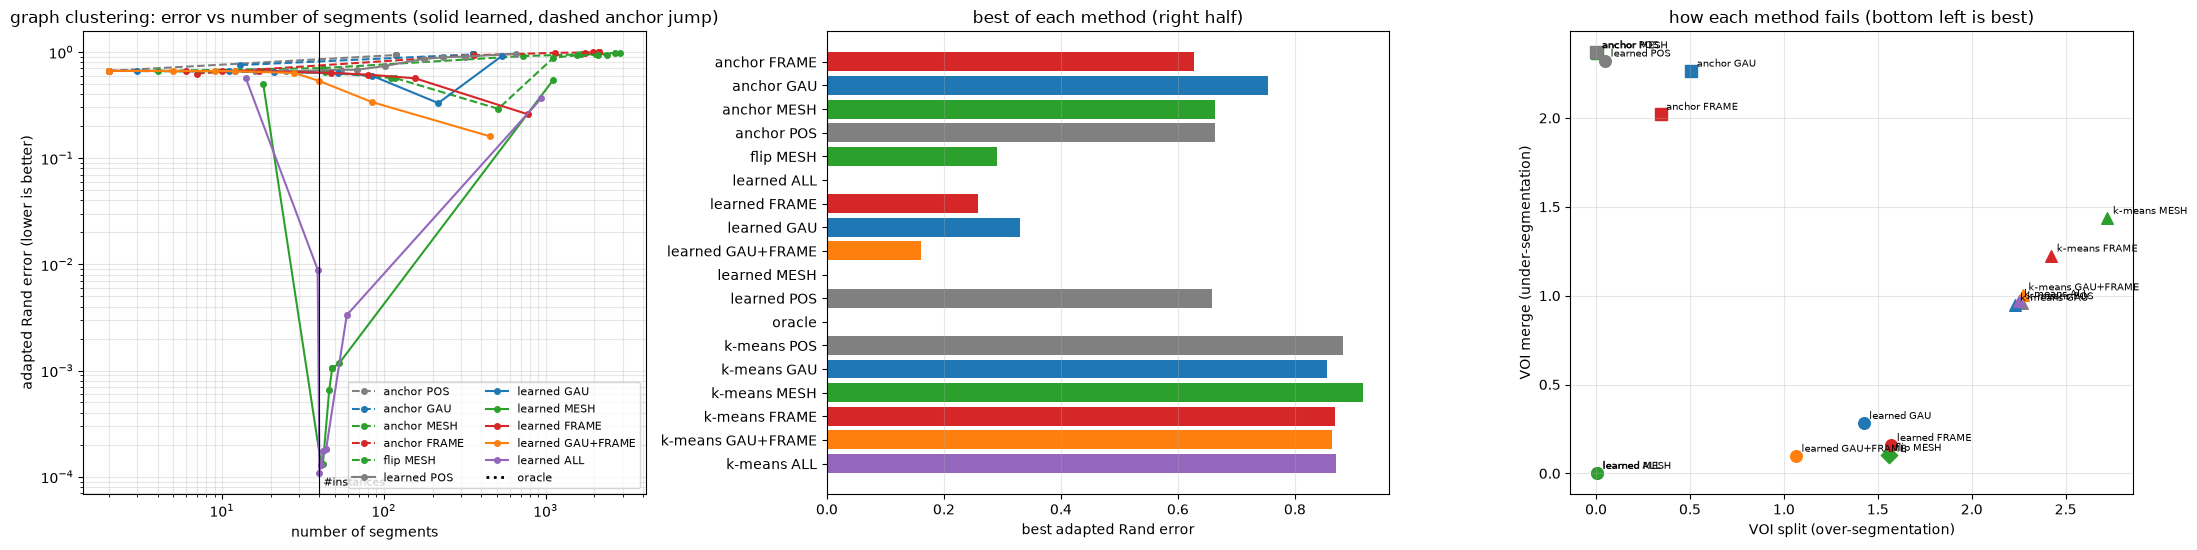

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(22, 5.6))
mcol = {"POS": "gray", "GAU": "tab:blue", "MESH": "tab:green", "FRAME": "tab:red", "GAU+FRAME": "tab:orange", "ALL": "tab:purple"}
for name in METHODS:
    d = SWEEP[SWEEP.method == name].sort_values("n_pred")
    if name == "oracle":
        axs[0].plot(d.n_pred, d.are, "k:", lw=2, label=name)
        continue
    kind, g = name.split()
    axs[0].plot(d.n_pred, d.are, "-" if kind == "learned" else "--", marker="o", ms=4, color=mcol[g], label=name)
axs[0].set_xscale("log"); axs[0].set_yscale("log")
axs[0].set_xlabel("number of segments"); axs[0].set_ylabel("adapted Rand error (lower is better)")
axs[0].axvline(n_gt, color="k", lw=0.8); axs[0].text(n_gt, axs[0].get_ylim()[0] * 1.2, " #instances", fontsize=8)
axs[0].set_title("graph clustering: error vs number of segments (solid learned, dashed anchor jump)")
axs[0].legend(fontsize=8, ncol=2); axs[0].grid(alpha=0.3, which="both")

names = list(TABLE.index)
axs[1].barh(range(len(names))[::-1], TABLE.are, color=["k" if n == "oracle" else mcol.get(n.split()[-1], "gray") for n in names])
axs[1].set_yticks(range(len(names))[::-1]); axs[1].set_yticklabels(names)
axs[1].set_xlabel("best adapted Rand error"); axs[1].set_title("best of each method (right half)"); axs[1].grid(axis="x", alpha=0.3)

for name in names:
    kind = name.split()[0]
    if kind in ("oracle",):
        continue
    g = name.split()[-1]
    axs[2].scatter(TABLE.loc[name, "voi_split"], TABLE.loc[name, "voi_merge"], color=mcol.get(g, "gray"),
                   marker={"anchor": "s", "flip": "D", "learned": "o", "k-means": "^"}[kind], s=70)
    axs[2].annotate(name, (TABLE.loc[name, "voi_split"], TABLE.loc[name, "voi_merge"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
axs[2].set_xlabel("VOI split (over-segmentation)"); axs[2].set_ylabel("VOI merge (under-segmentation)")
axs[2].set_title("how each method fails (bottom left is best)"); axs[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

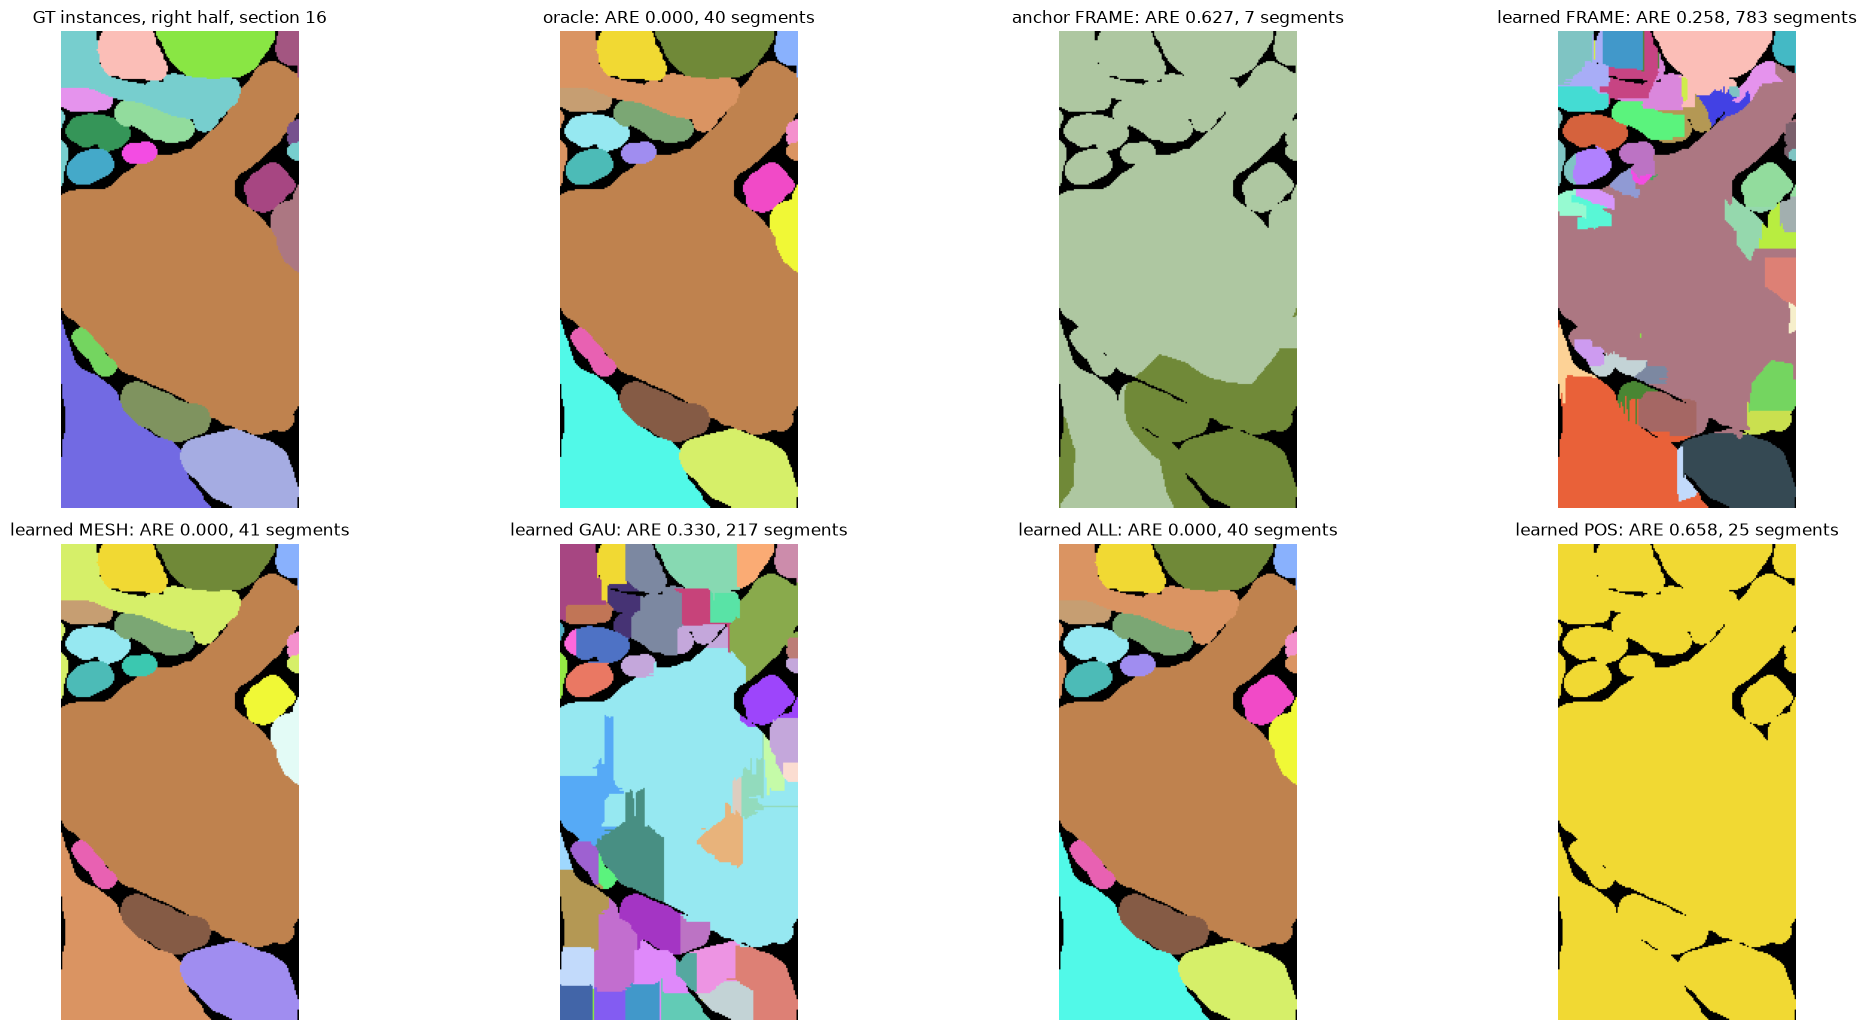

In [16]:
k = nz // 2
show = ["oracle", "anchor FRAME", "learned FRAME", "learned MESH", "learned GAU", "learned ALL", "learned POS"]
fig, axs = plt.subplots(2, 4, figsize=(22, 10.4))
x0r = HALF
lab_img = RAND[LAB[k, :, x0r:]]
axs[0, 0].imshow(lab_img, aspect=vy / vx); axs[0, 0].set_title(f"GT instances, right half, section {k}")
for a, name in zip(axs.ravel()[1:], show):
    seg = np.zeros(LAB.shape, np.int64)
    segN = np.zeros(N, np.int64)
    segN[RN] = BEST_LAB[name] + 1
    seg[FG] = segN
    r = TABLE.loc[name]
    a.imshow(rgb_of(seg[k, :, x0r:] + 1) * (seg[k, :, x0r:, None] > 0), aspect=vy / vx)
    a.set_title(f"{name}: ARE {r.are:.3f}, {int(r.n_pred)} segments")
for a in axs.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

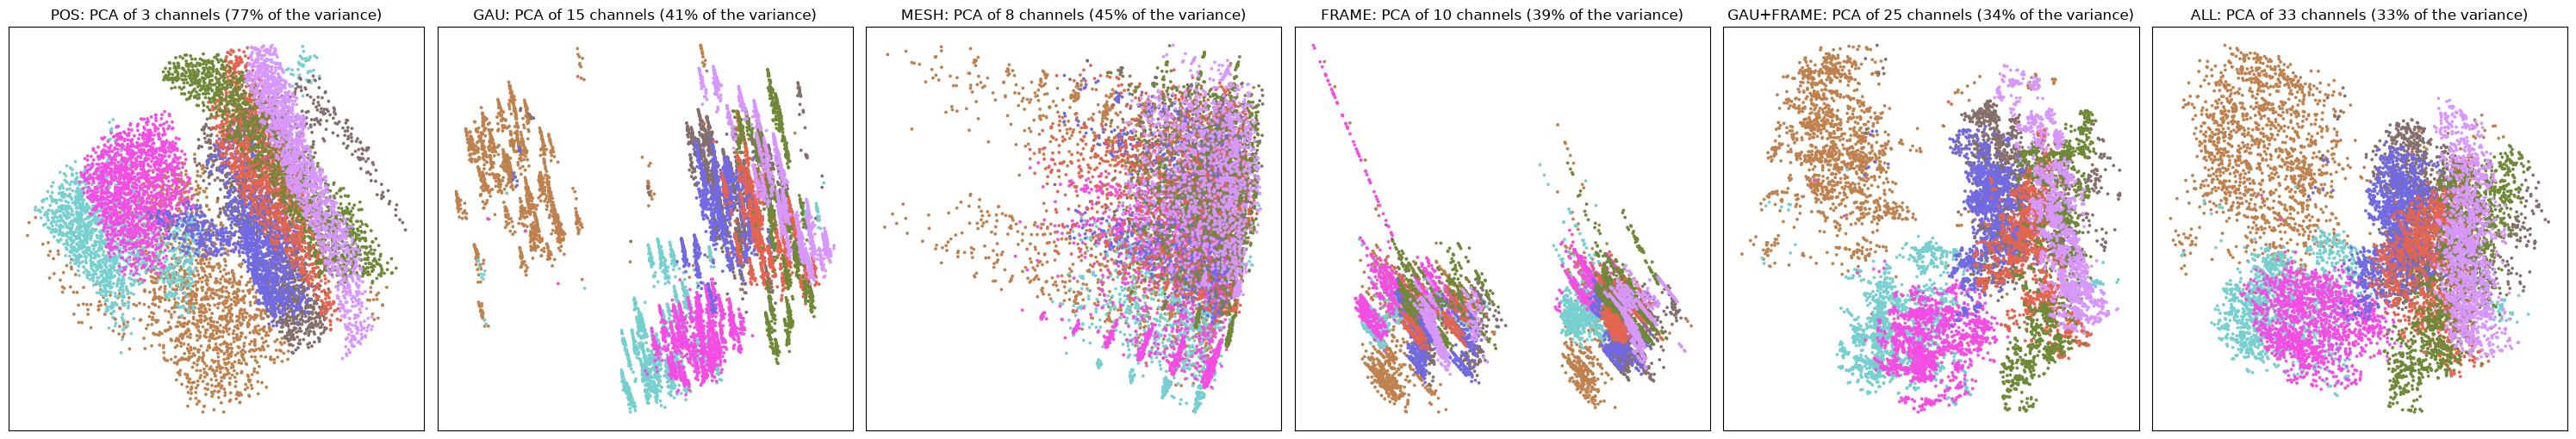

In [17]:
# 2-D view of the feature spaces: the 8 largest instances of the block, PCA of the standardised channels of each group
big = IDS[:8]
sel = np.concatenate([np.flatnonzero(LAB_N == i)[np.random.default_rng(SEED).permutation(CNT[int(i)])[:1500]] for i in big])
fig, axs = plt.subplots(1, 6, figsize=(30, 5.2))
for a, (g, chs) in zip(axs, LEARN_GROUPS.items()):
    X = np.stack([F[c][sel] for c in chs], axis=1).astype(np.float64)
    X = (X - X.mean(0)) / np.maximum(X.std(0), 1e-9)
    U, S, Vt = np.linalg.svd(X - X.mean(0), full_matrices=False)
    Y = U[:, :2] * S[:2]
    a.scatter(Y[:, 0], Y[:, 1], c=RAND[LAB_N[sel]], s=3)
    a.set_title(f"{g}: PCA of {len(chs)} channels ({(S[:2] ** 2).sum() / (S ** 2).sum():.0%} of the variance)")
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

## 9. Embeddings: PCA, t-SNE, UMAP

The per-voxel feature table is projected to 2-D with three methods, one feature group at a time, so that the picture
shows what each group contains and not only the mixture of all of them. The sample is stratified: up to `EMB_CAP`
voxels per instance, so the small instances are not swamped by the large ones. Every projection is standardised per
channel first.

Scores per projection (against the ground-truth instances of the sample):

* **kNN purity**: of the `EMB_K` nearest neighbours of a voxel, the share that belong to the same instance. Computed in
  the full feature space too, so the 2-D methods can be compared with the space they came from.
* **ARI**: adjusted Rand index of k-means with as many clusters as there are instances in the sample, run on the 2-D
  embedding. Only a sanity check: the embedding is not built to be clustered by k-means.

In [18]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
import umap

EMB_CAP = 600                      # voxels per instance in the embedding sample (every instance is represented)
EMB_K = 15                         # neighbours for the kNN purity
EMB_GROUPS = ("GAU", "MESH", "FRAME", "GAU+FRAME", "ALL")
rng = np.random.default_rng(SEED)
ES = np.concatenate([rng.choice(np.flatnonzero(LAB_N == i), min(CNT[int(i)], EMB_CAP), replace=False) for i in IDS])
ES_GT = LAB_N[ES]
N_ES_INST = len(np.unique(ES_GT))
print(f"sample: {len(ES):,} voxels, {N_ES_INST} instances, at most {EMB_CAP} per instance")


def standardized(chs):
    X = np.stack([F[c][ES] for c in chs], axis=1).astype(np.float64)
    return (X - X.mean(0)) / np.maximum(X.std(0), 1e-9)


def knn_purity(X, labels, k=EMB_K):
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    return float((labels[idx[:, 1:]] == labels[:, None]).mean())


def kmeans_ari(Y, labels):
    lab = KMeans(n_clusters=N_ES_INST, n_init=4, random_state=SEED).fit_predict(Y)
    return adjusted_rand_score(labels, lab)


X_RAW = {g: standardized(LEARN_GROUPS[g]) for g in EMB_GROUPS}
EMB = {}          # (method, group) -> (n, 2)
SCORE = []
t0 = time.time()
for g in EMB_GROUPS:
    X = X_RAW[g]
    pca = PCA(n_components=min(X.shape[1], 10), random_state=SEED).fit(X)
    Y = pca.transform(X)[:, :2]
    EMB[("PCA", g)] = Y
    SCORE.append(dict(group=g, space=f"raw ({X.shape[1]} ch)", purity=knn_purity(X, ES_GT), ari=np.nan,
                      var_pc2=pca.explained_variance_ratio_[:2].sum()))
    SCORE.append(dict(group=g, space="PCA 2-D", purity=knn_purity(Y, ES_GT), ari=kmeans_ari(Y, ES_GT), var_pc2=np.nan))
print(f"PCA done: {time.time() - t0:.0f} s")

/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sample: 36,552 voxels, 64 instances, at most 600 per instance
PCA done: 26 s


In [19]:
t0 = time.time()
for g in EMB_GROUPS:
    X = X_RAW[g]
    Y = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED, n_jobs=-1).fit_transform(X)
    EMB[("t-SNE", g)] = Y
    SCORE.append(dict(group=g, space="t-SNE 2-D", purity=knn_purity(Y, ES_GT), ari=kmeans_ari(Y, ES_GT), var_pc2=np.nan))
    print(f"  t-SNE {g}: {time.time() - t0:.0f} s")
for g in EMB_GROUPS:
    X = X_RAW[g]
    Y = umap.UMAP(n_neighbors=EMB_K, min_dist=0.1, n_components=2, random_state=SEED).fit_transform(X)
    EMB[("UMAP", g)] = Y
    SCORE.append(dict(group=g, space="UMAP 2-D", purity=knn_purity(Y, ES_GT), ari=kmeans_ari(Y, ES_GT), var_pc2=np.nan))
    print(f"  UMAP {g}: {time.time() - t0:.0f} s")
SCORE = pd.DataFrame(SCORE)
print(f"done in {time.time() - t0:.0f} s")

  t-SNE GAU: 57 s
  t-SNE MESH: 92 s
  t-SNE FRAME: 121 s
  t-SNE GAU+FRAME: 161 s
  t-SNE ALL: 203 s


/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP GAU: 238 s


/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP MESH: 253 s


/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP FRAME: 285 s


/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP GAU+FRAME: 300 s


/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/nvidia/anaconda3/envs/ncntm/lib/python3.15/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  UMAP ALL: 322 s
done in 322 s


In [20]:
TBL = pd.DataFrame(index=list(EMB_GROUPS))
TBL["purity: raw"] = SCORE[SCORE.space.str.startswith("raw")].set_index("group").purity
for m in ("PCA", "t-SNE", "UMAP"):
    TBL[f"purity: {m}"] = SCORE[SCORE.space.str.startswith(m)].set_index("group").purity
for m in ("PCA", "t-SNE", "UMAP"):
    TBL[f"ARI: {m}"] = SCORE[SCORE.space.str.startswith(m)].set_index("group").ari
print("PCA: share of the variance in the first two components:",
      {g: round(float(SCORE[(SCORE.group == g) & SCORE.var_pc2.notna()].var_pc2.iloc[0]), 3) for g in EMB_GROUPS})
display(TBL.style.format("{:.3f}"))

PCA: share of the variance in the first two components: {'GAU': 0.335, 'MESH': 0.422, 'FRAME': 0.359, 'GAU+FRAME': 0.284, 'ALL': 0.285}


,purity: raw,purity: PCA,purity: t-SNE,purity: UMAP,ARI: PCA,ARI: t-SNE,ARI: UMAP
GAU,0.851,0.228,0.864,0.838,0.061,0.366,0.323
MESH,0.602,0.201,0.572,0.504,0.050,0.096,0.081
FRAME,0.820,0.200,0.819,0.801,0.037,0.230,0.201
GAU+FRAME,0.822,0.474,0.835,0.802,0.278,0.276,0.204
ALL,0.763,0.367,0.780,0.726,0.249,0.282,0.195


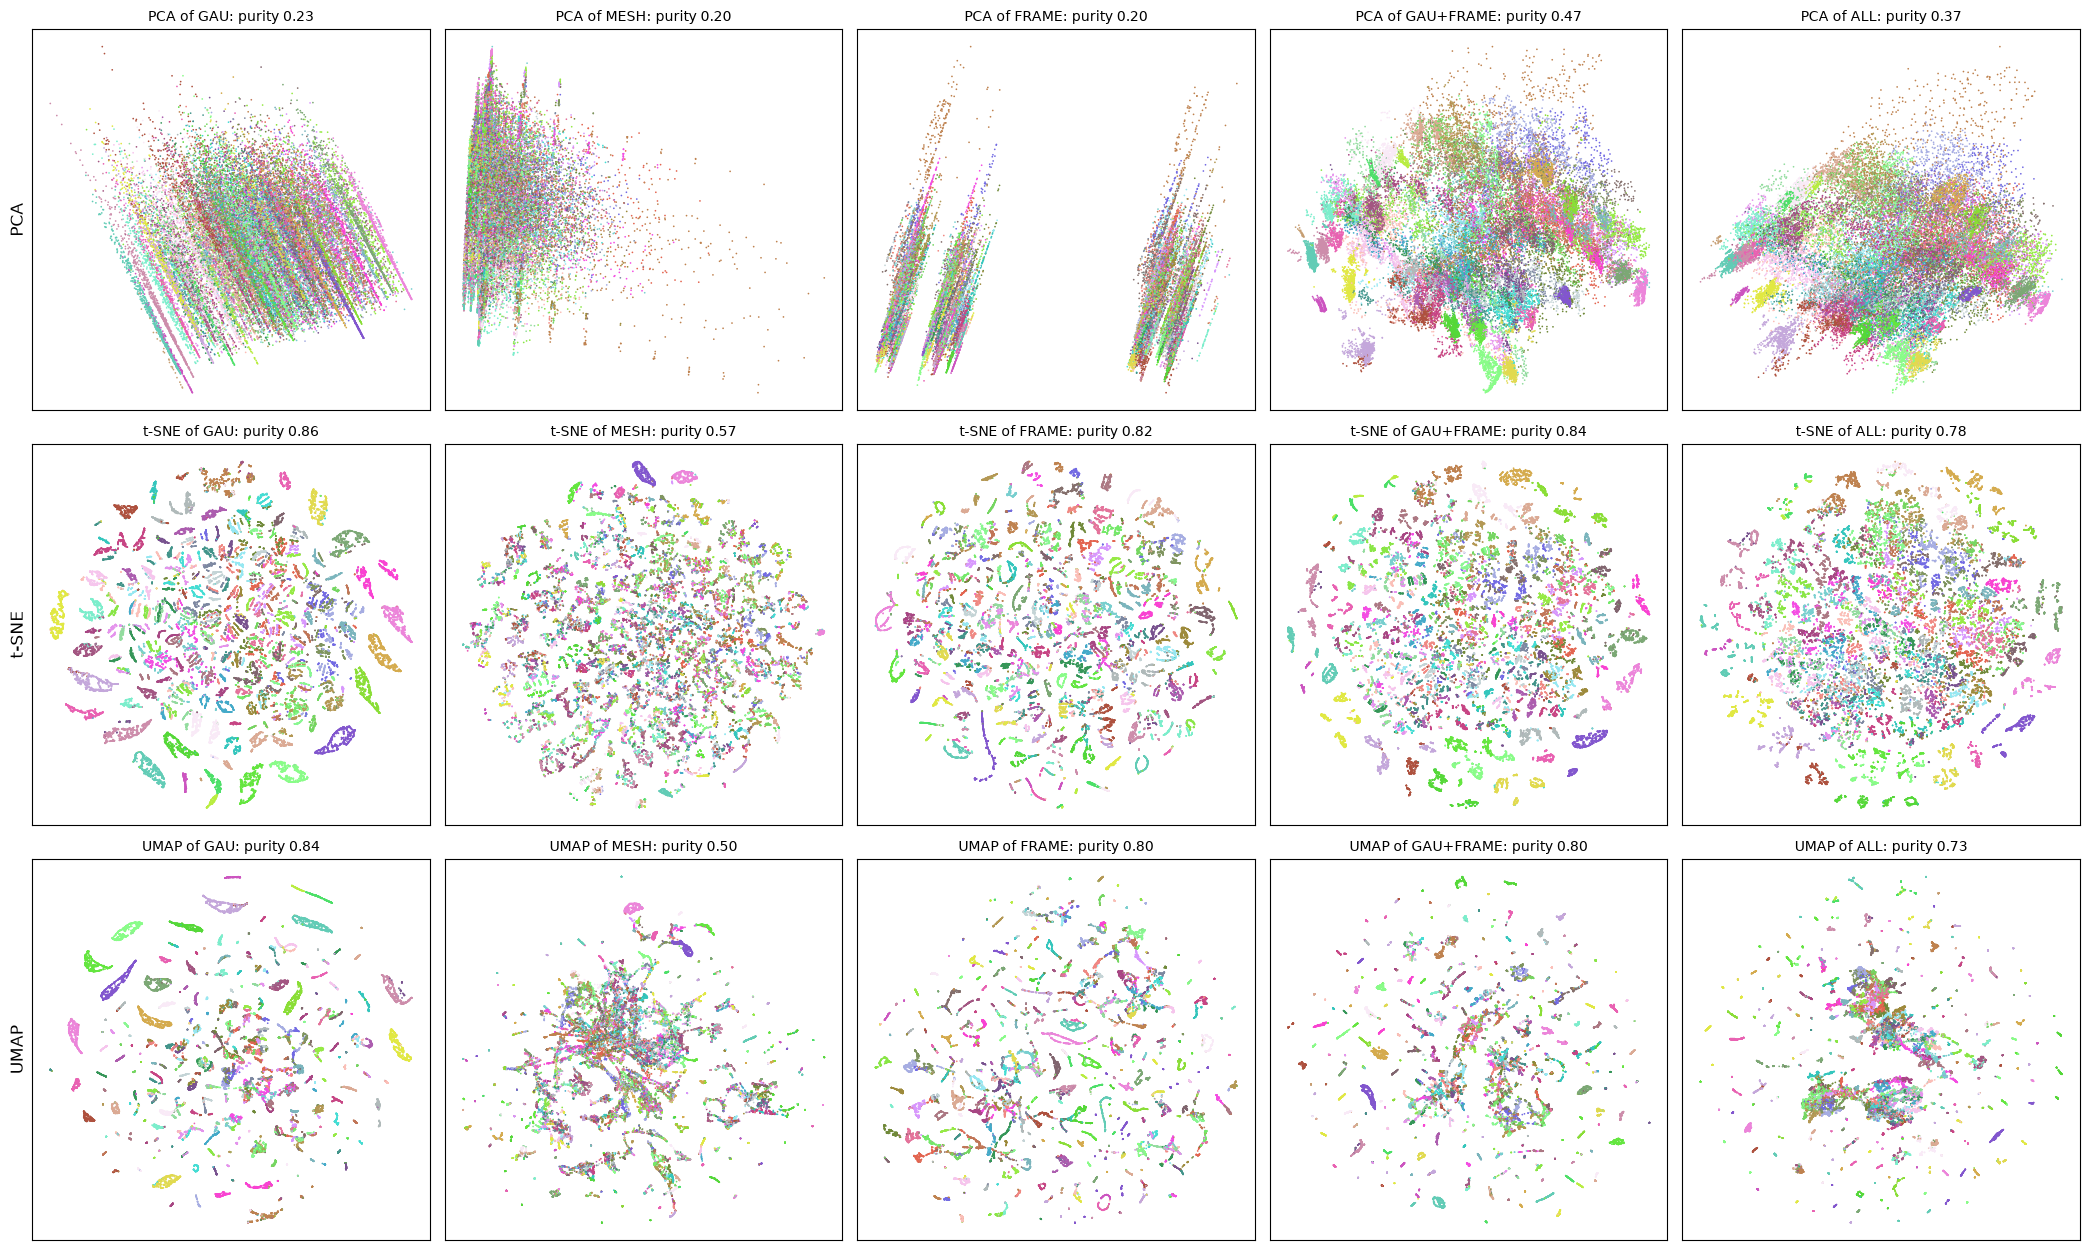

In [21]:
rows = [("PCA", "PCA"), ("t-SNE", "t-SNE"), ("UMAP", "UMAP")]
fig, axs = plt.subplots(len(rows), len(EMB_GROUPS), figsize=(4.2 * len(EMB_GROUPS), 4.2 * len(rows)))
order = rng.permutation(len(ES))                      # draw the instances in random order so none hides another
for r_, (m, _) in enumerate(rows):
    for c_, g in enumerate(EMB_GROUPS):
        a = axs[r_, c_]
        Y = EMB[(m, g)]
        a.scatter(Y[order, 0], Y[order, 1], c=RAND[ES_GT[order]], s=1.5, linewidths=0)
        a.set_xticks([]); a.set_yticks([])
        pur = SCORE[(SCORE.group == g) & SCORE.space.str.startswith(m)].purity.iloc[0]
        a.set_title(f"{m} of {g}: purity {pur:.2f}", fontsize=10)
        if c_ == 0:
            a.set_ylabel(m, fontsize=12)
plt.tight_layout()
plt.show()

## 8. Findings

The numbers below are filled in from the tables above (block, right half for the clustering).

In [22]:
from IPython.display import Markdown, display

best_ch = AUC.sort_values("auc", ascending=False).head(3)
t = TABLE
f = []
f.append(f"**Block.** {len(IDS)} instances, {N:,} labelled voxels; {(bin_of == 0).mean():.0%} of them are contact voxels "
         f"(a neighbour of another instance), {int(np.sum(DIFF)):,} of {len(DIFF):,} voxel pairs ({DIFF.mean():.1%}) join two instances, "
         f"{(DIFF[EAX == 0]).mean():.1%} of the pairs along z but {(DIFF[EAX == 2]).mean():.1%} along x.")
f.append(f"**1. Decoding the owner from the closest primitive.** wiremesh (inset) {DECODE.loc['wiremesh', 'accuracy']:.1%}, "
         f"wiremesh (tied) {DECODE.loc['wiremesh (tied)', 'accuracy']:.1%}, gaussian {DECODE.loc['gaussian', 'accuracy']:.1%}, "
         f"frame {DECODE.loc['frame', 'accuracy']:.1%}, frame d / r {DECODE.loc['frame (d / r)', 'accuracy']:.1%}, "
         f"frame d - r {DECODE.loc['frame (d - r)', 'accuracy']:.1%}. "
         f"On the contact voxels alone: gaussian {DECODE.loc['gaussian', 'contact_accuracy']:.1%}, frame {DECODE.loc['frame', 'contact_accuracy']:.1%}, "
         f"frame d / r {DECODE.loc['frame (d / r)', 'contact_accuracy']:.1%}, wiremesh (tied) {DECODE.loc['wiremesh (tied)', 'contact_accuracy']:.1%}. "
         "The wiremesh is the exact boundary: with the tie broken (0.5 nm inset) every voxel finds its own surface. "
         f"The {int((DEC['wiremesh (tied)'] != LAB_N).sum()):,} wrong owners of the tied version are voxels whose closest face is one of the two coincident faces of a contact "
         "(the face belongs to the neighbour, the voxel lies in front of it). The blobs and the axes are low-pass versions of the shape: "
         "blobs of neighbouring instances overlap at a contact, and a skeleton knows nothing about how far the instance extends from its axis, so the closest axis of a thin neighbour beats the axis of a fat instance.")
f.append(f"**2. Single channels.** Best AUC of a jump `|c(a) - c(b)|` for 'different instance': "
         + ", ".join(f"`{k}` {v:.2f}" for k, v in best_ch.auc.items())
         + ". They are the direction channels (`m_u*`, soft blob mean `g_smu*`), not the positions of the closest primitive: the closest surface "
           "point is almost the same on both sides of a contact (`m_q*` ~ 0.6-0.8, `m_sd` ~ 0.5), what flips is the direction from the surface to the voxel. "
           "The `POS` channels only say that z-steps cross contacts far more often than x-steps (`px`, `py` below 0.5).")
f.append("**3. Learned affinity (trained on the left half, scored on the right).** AUC / average precision (chance AP "
         f"{DIFF[ti].mean():.3f}): " + "; ".join(f"{g} {r.auc:.3f} / {r.average_precision:.3f}" for g, r in LEARNED.iterrows()) + ".")
f.append("**4. Clustering into instances (adapted Rand error, lower is better; best of the sweep).** "
         + "; ".join(f"{n} {t.loc[n, 'are']:.3f}" for n in t.index if not n.startswith("k-means"))
         + f". Feature-space k-means with K = {n_gt} (no neighbourhood): ARE {t.loc[[n for n in t.index if n.startswith('k-means')], 'are'].min():.2f}-"
           f"{t.loc[[n for n in t.index if n.startswith('k-means')], 'are'].max():.2f}, ARI at most {KM.ari.max():.2f}.")
for x in f:
    display(Markdown("- " + x))

- **Block.** 64 instances, 2,895,081 labelled voxels; 21% of them are contact voxels (a neighbour of another instance), 128,153 of 8,272,828 voxel pairs (1.5%) join two instances, 4.0% of the pairs along z but 0.4% along x.

- **1. Decoding the owner from the closest primitive.** wiremesh (inset) 100.0%, wiremesh (tied) 95.5%, gaussian 97.2%, frame 70.4%, frame d / r 91.7%, frame d - r 90.5%. On the contact voxels alone: gaussian 87.6%, frame 54.1%, frame d / r 74.5%, wiremesh (tied) 91.9%. The wiremesh is the exact boundary: with the tie broken (0.5 nm inset) every voxel finds its own surface. The 130,611 wrong owners of the tied version are voxels whose closest face is one of the two coincident faces of a contact (the face belongs to the neighbour, the voxel lies in front of it). The blobs and the axes are low-pass versions of the shape: blobs of neighbouring instances overlap at a contact, and a skeleton knows nothing about how far the instance extends from its axis, so the closest axis of a thin neighbour beats the axis of a fat instance.

- **2. Single channels.** Best AUC of a jump `|c(a) - c(b)|` for 'different instance': `g_smuz` 0.86, `m_uz` 0.85, `g_smuy` 0.84. They are the direction channels (`m_u*`, soft blob mean `g_smu*`), not the positions of the closest primitive: the closest surface point is almost the same on both sides of a contact (`m_q*` ~ 0.6-0.8, `m_sd` ~ 0.5), what flips is the direction from the surface to the voxel. The `POS` channels only say that z-steps cross contacts far more often than x-steps (`px`, `py` below 0.5).

- **3. Learned affinity (trained on the left half, scored on the right).** AUC / average precision (chance AP 0.014): POS 0.761 / 0.044; GAU 0.924 / 0.261; MESH 1.000 / 1.000; FRAME 0.909 / 0.210; GAU+FRAME 0.963 / 0.431; ALL 1.000 / 1.000.

- **4. Clustering into instances (adapted Rand error, lower is better; best of the sweep).** anchor FRAME 0.627; anchor GAU 0.753; anchor MESH 0.663; anchor POS 0.663; flip MESH 0.292; learned ALL 0.000; learned FRAME 0.258; learned GAU 0.330; learned GAU+FRAME 0.161; learned MESH 0.000; learned POS 0.658; oracle 0.000. Feature-space k-means with K = 40 (no neighbourhood): ARE 0.85-0.92, ARI at most 0.10.

**Reading** (for the default block; re-check it if you change the parameters).

* **The wiremesh holds the instance boundary**; the learned affinity on its eight channels (a distance, a closest point
  and, above all, the direction from the surface to the voxel) recovers every instance of the right half like the oracle
  does, with a model trained on the other half. This is not a surprise (the mesh *is* the surface of each instance), but it
  shows which feature carries it: the *direction flips* across a contact while the closest point does not move.
* **The gaussian and the frame hold the instance, not its boundary.** At 3 000 voxels per blob and one skeleton per
  instance they place a contact only to within a blob or a neurite radius. Combined (`GAU+FRAME`) they are clearly better
  than either alone, but still over-segment (precision high, recall low) and cannot find the thin contact sheets.
* **Without a neighbourhood nothing clusters.** K-means on any feature group has an ARI under 0.11: the instances are long,
  thin, intertwined, and a feature that tells where the nearest primitive is (`g_mu*`, `m_q*`, `f_a*`) is a quantised
  position, which `POS` shows is not enough either. The graph (adjacent voxels) is what turns features into instances.
* **Unsupervised anchor jumps fail.** The jump of the closest primitive is as large inside an instance (from one blob or
  axis point to the next) as across a contact. The learned model finds the combinations that are not (entropy and Mahalanobis
  of the blob, distance / radius of the axis). The one label-free affinity that works at all is the wiremesh **flip** (how
  much the direction surface -> voxel turns): ARE 0.29, level with the learned frame, against 0.66 for the closest-point jump.

**Caveats.** One block of one volume (`BLOCK_ORIGIN`, `BLOCK_SHAPE`), the representations are built from the GT instances and
the blob count is fixed by `VOX_PER_BLOB`; more blobs or a denser skeleton would push `GAU` and `FRAME` towards the
wiremesh. A learned affinity is a ceiling on what the channels can say, not a method for raw EM.